# ECE1512 Project B, Part 3: DNN-Based Image Compression (RDVQ reproduction, Colab)

Run top to bottom on a **GPU runtime** (Runtime > Change runtime type > GPU). The dataset is downloaded automatically from Hugging Face (manual zip upload is the fallback); the instructor helper modules are written to disk by the cells in Section 1b.

**What this notebook reproduces.** A compact, single-scale RDVQ-style codec (Jiang et al., CVPR 2026): conv encoder -> latent vectors -> codebook with *soft* assignment during training and *hard* nearest-codeword indices at evaluation -> conv decoder, trained with `L = (MSE + L_codebook) + lambda * R_soft`. Section 4a states exactly which parts of the paper's objective and entropy model are reproduced and which are simplified.

### Rubric map (Part 3, 30 pts)

| Rubric bullet | Pts | Where it is produced |
|---|---|---|
| Encoder/decoder architecture, codebook size, how latent vectors become stored integer indices | 12 | Section 6-A (architecture table, latent shape, index map, real bitstream round trip, rate accounting) |
| Rate-distortion objective: each term, formula, role | 8 | Sections 4 and 4a (math, exact mapping to the paper), Section 6-B (measured MSE / codebook / R / lambda*R terms, rate-term activity, per-epoch curves) |
| Soft (training) vs hard (evaluation) quantization and how the discrepancy is handled | 10 | Section 2 (implementation), Section 6-C (gradient-path test, temperature sweep, soft vs hard gap, optional straight-through vs fully-soft training) |
| Student TODOs: `soft_quantize`, `psnr_per_image`, `ssim_per_image` | (prereq.) | Sections 2, 3 (checked against the provided tests and the TorchMetrics reference) |
| Compare RDVQ with earlier learned codecs, differences from the paper | (report) | Report Part 3 text; summary in Section 7 |

Sections 8-9 (test evaluation, actual file bitstream, JPEG comparison) are the hand-off to **Part 4** and reuse the provided helper code unchanged.

## 1. Setup

In [1]:
import sys, os, io, json, math, random, time, subprocess, zipfile, copy, importlib
from pathlib import Path
from datetime import datetime
from functools import partial

try:
    import torchmetrics                      # needed by metrics.py (reference SSIM)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torchmetrics'])
    import torchmetrics

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print('PyTorch', torch.__version__, '| TorchMetrics', torchmetrics.__version__, '| device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU. Runtime > Change runtime type > GPU, then restart.')

PyTorch 2.14.1+cu130 | TorchMetrics 1.9.0 | device: cuda
GPU: Tesla T4


## 1b. Helper modules (instructor-provided, written verbatim)

The cells below write the course helper files (`data.py`, `model.py`, `engine.py`, `codec.py`, `arithmetic.py`, `entropy_context.py`, `comparison.py`, `metrics.py`, `checks.py`, `instructor/warm_start.py`) into `dnn_compression_notebook/`. They are **unchanged**; all student work is in Sections 2, 3, 4a and 6 (Section 4a subclasses `CompressionModel` inside the notebook; the helper files themselves are not edited). In a cloned GitHub repo the same files live in `helpers/`.

In [2]:
PROJECT_DIR = Path.cwd() / 'dnn_compression_notebook'
(PROJECT_DIR / 'instructor').mkdir(parents=True, exist_ok=True)
print('Helper folder:', PROJECT_DIR)

Helper folder: /content/dnn_compression_notebook


In [3]:
%%writefile dnn_compression_notebook/data.py
"""Clean RGB images, prepared dataset splits, and saved manifests."""
import json
import random
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def source_group(path):
    # For this dataset: BC38_R02.png_crop_370.png -> BC38_R02.png.
    return Path(path).name.split('_crop_')[0]


def split_images(root, manifest, seed=1512):
    root, manifest = Path(root).resolve(), Path(manifest)
    if not root.is_dir():
        raise FileNotFoundError(f'Image directory not found: {root}')
    split_dirs = {s: (root / s).is_dir() for s in ('train', 'val', 'test')}
    prepared = all(split_dirs.values())
    if any(split_dirs.values()) and not prepared:
        raise ValueError('Prepared dataset requires train, val, and test folders')
    if manifest.exists():
        record = json.loads(manifest.read_text())
        if record['seed'] != seed or record['root'] != str(root):
            raise ValueError('Existing manifest uses another root/seed. Choose a new manifest path.')
        splits = record['splits']
    elif prepared:
        splits = {s: [str(p.relative_to(root)) for p in sorted((root / s).rglob('*'))
                      if p.is_file() and p.suffix.lower() in EXTENSIONS]
                  for s in ('train', 'val', 'test')}
        record = dict(root=str(root), seed=seed, split_rule='predefined_directories', splits=splits)
        manifest.parent.mkdir(parents=True, exist_ok=True)
        manifest.write_text(json.dumps(record, indent=2))
    else:
        paths = sorted(p for p in root.rglob('*') if p.suffix.lower() in EXTENSIONS and p.is_file())
        groups = sorted({source_group(p) for p in paths})
        if len(groups) < 3:
            raise ValueError('At least three source-image groups are required.')
        random.Random(seed).shuffle(groups)
        nv = max(1, round(0.15 * len(groups)))
        nt = max(1, round(0.15 * len(groups)))
        group_sets = dict(val=set(groups[:nv]), test=set(groups[nv:nv+nt]),
                          train=set(groups[nv+nt:]))
        splits = {s: [str(p.relative_to(root)) for p in paths if source_group(p) in gs]
                  for s, gs in group_sets.items()}
        record = dict(root=str(root), seed=seed, group_rule='filename before _crop_', splits=splits)
        manifest.parent.mkdir(parents=True, exist_ok=True)
        manifest.write_text(json.dumps(record, indent=2))
    seen = set()
    for s in ('train', 'val', 'test'):
        if not splits[s]:
            raise ValueError(f'Empty {s} split')
        if prepared:
            if any(Path(p).parts[0] != s for p in splits[s]):
                raise ValueError('Manifest does not match the prepared split folders')
        else:
            groups = {source_group(p) for p in splits[s]}
            if seen & groups:
                raise ValueError('Source-image leakage across splits')
            seen |= groups
        if not all((root / p).is_file() for p in splits[s]):
            raise FileNotFoundError(f'Missing images in {s} manifest')
    return {s: [root / p for p in paths] for s, paths in splits.items()}


class ImageDataset(Dataset):
    def __init__(self, paths, crop_size=64, train=False):
        self.paths, self.crop_size, self.train = list(paths), int(crop_size), train
        if self.crop_size < 1 or not self.paths:
            raise ValueError('Require positive crop_size and nonempty paths')

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
        size = self.crop_size
        w, h = image.size
        if min(w, h) < size:
            scale = size / min(w, h)
            image = image.resize((round(w * scale), round(h * scale)), Image.Resampling.BICUBIC)
        w, h = image.size
        left = random.randint(0, w-size) if self.train else (w-size)//2
        top = random.randint(0, h-size) if self.train else (h-size)//2
        image = image.crop((left, top, left+size, top+size))
        if self.train and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        return torch.from_numpy(np.array(image, dtype=np.float32) / 255).permute(2, 0, 1)


def make_loaders(splits, crop_size=64, batch_size=8, seed=1512, limits=None):
    loaders = {}
    for offset, s in enumerate(('train', 'val', 'test')):
        paths = list(splits[s])
        # Sample across source groups instead of taking a sorted prefix.
        random.Random(seed + offset).shuffle(paths)
        if limits and limits.get(s):
            paths = paths[:limits[s]]
        loaders[s] = DataLoader(ImageDataset(paths, crop_size, train=s == 'train'),
                                batch_size=batch_size, shuffle=s == 'train', num_workers=0,
                                generator=torch.Generator().manual_seed(seed + offset))
    return loaders

Writing dnn_compression_notebook/data.py


In [4]:
%%writefile dnn_compression_notebook/model.py
"""Compact, single-scale RDVQ-inspired teaching model; no RDVQ dependency."""
import math
import torch
from torch import nn
from torch.nn import functional as F


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1),
                                 nn.SiLU(), nn.Conv2d(channels, channels, 3, padding=1))

    def forward(self, x):
        return x + self.net(x)


class Encoder(nn.Module):
    def __init__(self, width=24, latent_dim=8, levels=3, res_blocks=1):
        super().__init__()
        layers, cin = [], 3
        for i in range(levels):
            cout = width * min(2 ** i, 2)
            layers += [nn.Conv2d(cin, cout, 4, stride=2, padding=1), nn.SiLU()]
            layers += [ResidualBlock(cout) for _ in range(res_blocks)]
            cin = cout
        layers += [nn.Conv2d(cin, latent_dim, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, width=24, latent_dim=8, levels=3, res_blocks=1):
        super().__init__()
        channels = [width * min(2 ** i, 2) for i in range(levels)]
        layers = [nn.Conv2d(latent_dim, channels[-1], 1)]
        cin = channels[-1]
        for cout in reversed(channels):
            layers += [ResidualBlock(cin) for _ in range(res_blocks)]
            layers += [nn.Upsample(scale_factor=2, mode='nearest'),
                       nn.Conv2d(cin, cout, 3, padding=1), nn.SiLU()]
            cin = cout
        layers += [nn.Conv2d(cin, 3, 3, padding=1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class CompressionModel(nn.Module):
    """Inject the student's differentiable soft_quantize(flat, codebook, tau).

    Input/output RGB in [0,1]. Training uses soft vectors (or optional hard
    forward/soft backward). Evaluation always uses nearest codebook vectors.
    """
    def __init__(self, soft_quantize, width=24, latent_dim=8, levels=3,
                 codebook_size=64, straight_through=False, res_blocks=1):
        super().__init__()
        if min(width, latent_dim, levels) < 1 or levels > 4 or codebook_size < 2:
            raise ValueError('Require positive width/dim, levels in 1..4, K >= 2')
        if not isinstance(res_blocks, int) or res_blocks < 1:
            raise ValueError('res_blocks must be a positive integer')
        self.config = dict(width=width, latent_dim=latent_dim, levels=levels,
                           codebook_size=codebook_size, straight_through=straight_through)
        # Preserve old checkpoint configs and bitstream fingerprints at depth 1.
        if res_blocks != 1:
            self.config['res_blocks'] = res_blocks
        self.soft_quantize = soft_quantize
        self.factor = 2 ** levels
        self.encoder = Encoder(width, latent_dim, levels, res_blocks)
        self.decoder = Decoder(width, latent_dim, levels, res_blocks)
        self.codebook = nn.Parameter(torch.randn(codebook_size, latent_dim) * 0.1)
        self.prior_logits = nn.Parameter(torch.zeros(codebook_size))

    def encode(self, x):
        h, w = x.shape[-2:]
        padded = F.pad(x, (0, (-w) % self.factor, 0, (-h) % self.factor), mode='replicate')
        return self.encoder(padded)

    def hard_indices(self, flat):
        # Hard nearest-neighbor path is provided; the soft path is the exercise.
        return (flat.square().sum(-1, keepdim=True) + self.codebook.square().sum(-1)
                - 2 * flat @ self.codebook.T).argmin(-1)

    def decode_indices(self, indices, height, width):
        z = F.embedding(indices, self.codebook).permute(0, 3, 1, 2).contiguous()
        return self.decoder(z)[..., :height, :width]

    def forward(self, x, temperature=0.5):
        b, _, h, w = x.shape
        z = self.encode(x)
        _, d, zh, zw = z.shape
        flat = z.permute(0, 2, 3, 1).reshape(-1, d)
        indices = self.hard_indices(flat)
        costs = -F.log_softmax(self.prior_logits, dim=0) / math.log(2)
        if self.training:
            soft, probabilities = self.soft_quantize(flat, self.codebook, temperature)
            quantized = soft
            if self.config['straight_through']:
                hard = F.embedding(indices, self.codebook)
                quantized = soft + (hard - soft).detach()
            bits = (probabilities * costs).sum()
        else:
            quantized = F.embedding(indices, self.codebook)
            bits = costs[indices].sum()
        zq = quantized.reshape(b, zh, zw, d).permute(0, 3, 1, 2).contiguous()
        return dict(reconstruction=self.decoder(zq)[..., :h, :w],
                    estimated_bpp=bits / (b * h * w),
                    indices=indices.reshape(b, zh, zw))

Writing dnn_compression_notebook/model.py


In [5]:
%%writefile dnn_compression_notebook/engine.py
"""Provided end-to-end training and hard-quantized evaluation."""
import csv
import json
import time
from pathlib import Path
import torch
from model import CompressionModel
from metrics import ssim_per_image


@torch.no_grad()
def evaluate(model, loader, device, rate_weight=0.01, *, psnr_fn=None, ssim_fn=None):
    model.eval()
    ssim_fn = ssim_per_image if ssim_fn is None else ssim_fn
    totals = dict(mse=0., psnr=0., ssim=0., estimated_bpp=0.)
    count = 0
    for x in loader:
        x = x.to(device)
        result = model(x)
        mse = (result['reconstruction'] - x).square().flatten(1).mean(1)
        n = len(x)
        totals['mse'] += mse.sum().item()
        totals['ssim'] += ssim_fn(result['reconstruction'], x).sum().item()
        psnr_values = (-10 * mse.clamp_min(1e-12).log10() if psnr_fn is None
                       else psnr_fn(result['reconstruction'], x))
        totals['psnr'] += psnr_values.sum().item()
        totals['estimated_bpp'] += result['estimated_bpp'].item() * n
        count += n
    if not count:
        raise ValueError('Empty evaluation loader')
    metrics = {k: v/count for k, v in totals.items()}
    metrics['loss'] = metrics['mse'] + rate_weight * metrics['estimated_bpp']
    return metrics


def load_checkpoint(path, soft_quantize, device='cpu'):
    state = torch.load(path, map_location=device, weights_only=True)
    model = CompressionModel(soft_quantize, **state['model_config']).to(device)
    coder_keys = {k for k in state['state_dict'] if k.startswith('coder_')}
    if coder_keys:
        if coder_keys != {'coder_left', 'coder_up'}:
            raise ValueError('Incomplete arithmetic context checkpoint')
        for key in sorted(coder_keys):
            model.register_buffer(key, state['state_dict'][key].clone().to(device))
    model.load_state_dict(state['state_dict'])
    return model.eval(), state


def fit(model, loaders, config, output_dir, device, *, psnr_fn=None, ssim_fn=None, loss_fn=None):
    output_dir = Path(output_dir)
    # Avoid silently replacing a previous experiment.
    output_dir.mkdir(parents=True, exist_ok=False)
    config = dict(config)
    (output_dir / 'config.json').write_text(json.dumps(config, indent=2))
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    epochs, rate_weight = int(config['epochs']), float(config['rate_weight'])
    start, end = float(config['temperature_start']), float(config['temperature_end'])
    if epochs < 1 or min(start, end, config['lr']) <= 0 or rate_weight < 0:
        raise ValueError('Invalid epochs, temperatures, lr, or rate_weight')
    best, history = float('inf'), []
    model.to(device)
    start_time = time.perf_counter()
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(epochs):
        tau = start * (end / start) ** (epoch / max(epochs-1, 1))
        model.train()
        total, count = 0., 0
        for x in loaders['train']:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            result = model(x, temperature=tau)
            if loss_fn is None:
                mse = (result['reconstruction'] - x).square().mean()
                loss = mse + rate_weight * result['estimated_bpp']
            else:
                loss = loss_fn(result, x, rate_weight)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite loss; check quantization/temperature/lr')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            total += loss.item() * len(x)
            count += len(x)
        val = evaluate(model, loaders['val'], device, rate_weight,
                       psnr_fn=psnr_fn, ssim_fn=ssim_fn)
        row = dict(epoch=epoch+1, temperature=tau, train_loss=total/count,
                   **{f'val_{k}': v for k, v in val.items()})
        history.append(row)
        if val['loss'] < best:
            best = val['loss']
            torch.save(dict(state_dict=model.state_dict(), model_config=model.config,
                            train_config=config, epoch=epoch+1, validation=val), output_dir/'best.pt')
        with (output_dir/'history.csv').open('w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=list(history[0]))
            writer.writeheader(); writer.writerows(history)
        torch.save(dict(state_dict=model.state_dict(), model_config=model.config,
                        train_config=config, epoch=epoch+1, validation=val,
                        optimizer=optimizer.state_dict()), output_dir/'last.pt')
        print(f"Epoch {epoch+1}/{epochs}: train={total/count:.5f}, hard val PSNR={val['psnr']:.2f}, SSIM={val['ssim']:.4f}, estimated bpp={val['estimated_bpp']:.4f}")
    with (output_dir/'history.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    resources = dict(device=str(device), training_seconds=time.perf_counter()-start_time,
                     parameter_count=sum(p.numel() for p in model.parameters()),
                     peak_allocated_gpu_mib=(torch.cuda.max_memory_allocated(device)/2**20
                                             if device.type == 'cuda' else None))
    (output_dir/'resources.json').write_text(json.dumps(resources, indent=2))
    print('Run resources:', resources)
    selected, _ = load_checkpoint(output_dir/'best.pt', model.soft_quantize, device)
    return selected, history

Writing dnn_compression_notebook/engine.py


In [6]:
%%writefile dnn_compression_notebook/metrics.py
"""RGB SSIM, using the same TorchMetrics protocol as JPEG restoration."""
import numpy as np
import torch
from torchmetrics.functional.image import structural_similarity_index_measure


def ssim_per_image(pred, target):
    """Return [B] SSIM values on [0,1] RGB, Gaussian window 11, sigma 1.5."""
    return structural_similarity_index_measure(pred.float(), target.float(),
        data_range=1.0, gaussian_kernel=True, sigma=1.5, kernel_size=11,
        reduction='none').reshape(-1)


def array_ssim(original, reconstruction):
    a=torch.from_numpy(np.array(original, dtype=np.float32, copy=True)).permute(2,0,1)[None]
    b=torch.from_numpy(np.array(reconstruction, dtype=np.float32, copy=True)).permute(2,0,1)[None]
    return float(ssim_per_image(b,a)[0])

Writing dnn_compression_notebook/metrics.py


In [7]:
%%writefile dnn_compression_notebook/checks.py
"""Student-facing behavioral checks; no reference implementation imported."""
import torch
from model import CompressionModel
from codec import compress, decompress


def check_soft_quantize(fn):
    x = torch.tensor([[0.25, 0.0], [1.5, 0.0]], dtype=torch.float64, requires_grad=True)
    codebook = torch.tensor([[0., 0.], [2., 0.], [0., 3.]], dtype=torch.float64, requires_grad=True)
    q, p = fn(x, codebook, 0.7)
    assert q.shape == x.shape and p.shape == (2, 3)
    assert torch.isfinite(q).all() and torch.isfinite(p).all() and (p >= 0).all()
    torch.testing.assert_close(p.sum(-1), torch.ones(2, dtype=p.dtype))
    # Relative probability fixes the distance scale/sign/temperature convention.
    expected_ratio = torch.tensor([3./0.7, -2./0.7], dtype=p.dtype)
    torch.testing.assert_close(p[:, 0].log() - p[:, 1].log(), expected_ratio)
    torch.testing.assert_close(q, p @ codebook)
    cold, _ = fn(x, codebook, 0.001)
    torch.testing.assert_close(cold, codebook[torch.tensor([0, 1])])
    _, hot = fn(x, codebook, 1e7)
    torch.testing.assert_close(hot, torch.full_like(hot, 1/3), atol=1e-6, rtol=1e-6)
    assert torch.autograd.gradcheck(lambda a, b: fn(a, b, 0.7)[0], (x, codebook))
    q.square().sum().backward()
    for t in (x, codebook):
        assert t.grad is not None and torch.isfinite(t.grad).all() and t.grad.abs().sum() > 0
    # An implementation that detaches everything must fail before training.
    print('Soft quantization: shape, values, temperature, and gradients passed.')


def check_pipeline(fn):
    torch.manual_seed(7)
    model = CompressionModel(fn, width=8, latent_dim=4, levels=2, codebook_size=7)
    x = torch.rand(2, 3, 19, 23)
    result = model(x)
    assert result['reconstruction'].shape == x.shape
    loss = (result['reconstruction']-x).square().mean() + .01*result['estimated_bpp']
    loss.backward()
    for name, parameters in [('encoder', model.encoder.parameters()),
                             ('decoder', model.decoder.parameters()),
                             ('codebook', [model.codebook]), ('prior', [model.prior_logits])]:
        grads = [p.grad for p in parameters]
        assert all(g is not None and torch.isfinite(g).all() for g in grads), name
        assert sum(g.abs().sum().item() for g in grads) > 0, name
    model.eval()
    with torch.no_grad():
        expected = model(x[:1])['reconstruction']
        stream = compress(model, x[:1])
        actual = decompress(model, stream)
    torch.testing.assert_close(actual, expected)
    assert actual.min() >= 0 and actual.max() <= 1
    print('End-to-end gradients and odd-size bitstream round trip passed.')

Writing dnn_compression_notebook/checks.py


In [8]:
%%writefile dnn_compression_notebook/codec.py
"""Decodable latent bitstreams: legacy zlib or trained-context arithmetic coding.

ECV1 decodes earlier zlib files. ECV2 chooses the smallest latent payload among
zlib, causal left-context arithmetic, and causal up-context arithmetic. Header
and shared checkpoint bytes are excluded from reported latent-only BPP.
"""
import hashlib
import json
import math
import struct
import zlib
import numpy as np
import torch
from arithmetic import encode as arithmetic_encode, decode as arithmetic_decode


def model_id(model, legacy=False):
    digest = hashlib.sha256(json.dumps(model.config, sort_keys=True).encode())
    for name, value in sorted(model.state_dict().items()):
        if legacy and name.startswith('coder_'):
            continue
        digest.update(name.encode())
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def _parts(stream):
    if stream[:4] not in (b'ECV1',b'ECV2') or len(stream) < 8:
        raise ValueError('Invalid teaching bitstream')
    length = struct.unpack('>I', stream[4:8])[0]
    if length < 1 or 8+length > len(stream):
        raise ValueError('Invalid bitstream header length')
    return stream[:4], json.loads(stream[8:8+length]), stream[8+length:]


def payload_size(stream):
    """Number of compressed latent bytes, excluding all container/header bytes."""
    return len(_parts(stream)[2])


def _packed_indices(ids, width):
    flat = np.asarray(ids, dtype=np.uint64).reshape(-1)
    bits = ((flat[:, None] >> np.arange(width-1, -1, -1, dtype=np.uint64)) & 1).astype(np.uint8)
    return np.packbits(bits.reshape(-1)).tobytes()


def _prior(model):
    return torch.softmax(model.prior_logits.detach().float().cpu(),dim=0).numpy()


@torch.no_grad()
def compress(model, x):
    if x.ndim != 4 or x.shape[0] != 1 or x.shape[1] != 3:
        raise ValueError('compress expects one RGB image [1,3,H,W]')
    model.eval()
    z = model.encode(x)
    flat = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
    ids = model.hard_indices(flat).cpu().numpy().astype(np.uint64).reshape(z.shape[-2],z.shape[-1])
    width = math.ceil(math.log2(model.config['codebook_size']))
    packed = _packed_indices(ids,width)
    zlib_payload = zlib.compress(packed)
    trained = hasattr(model,'coder_left') and hasattr(model,'coder_up')
    if trained:
        k=model.config['codebook_size']
        prior=_prior(model)
        choices=[zlib_payload,
                 arithmetic_encode(ids,k,prior,'left',model.coder_left.detach().cpu().numpy()),
                 arithmetic_encode(ids,k,prior,'up',model.coder_up.detach().cpu().numpy())]
        coding_mode=min(range(len(choices)),key=lambda i:len(choices[i]))
        payload=choices[coding_mode]
        magic=b'ECV2'
    else:
        payload=zlib_payload
        magic=b'ECV1'
    header=dict(height=x.shape[-2], width=x.shape[-1], zh=z.shape[-2],
                zw=z.shape[-1], bits=width, model_id=model_id(model))
    if trained:
        header['c']=coding_mode
        header['crc32']=zlib.crc32(packed)
    header=json.dumps(header,separators=(',', ':')).encode()
    return magic+struct.pack('>I',len(header))+header+payload


@torch.no_grad()
def decompress(model, stream):
    model.eval()
    magic,header,payload=_parts(stream)
    expected=model_id(model,legacy=(magic==b'ECV1'))
    if header['model_id'] != expected:
        raise ValueError('Decoder checkpoint does not match encoder checkpoint')
    h,w,zh,zw,bits=[header[k] for k in ('height','width','zh','zw','bits')]
    if min(h,w,zh,zw)<=0 or (zh,zw)!=(math.ceil(h/model.factor),math.ceil(w/model.factor)):
        raise ValueError('Invalid shape header')
    k=model.config['codebook_size']
    if bits!=math.ceil(math.log2(k)):
        raise ValueError('Invalid symbol width')
    if magic==b'ECV1' or header['c']==0:
        packed=zlib.decompress(payload)
        count=zh*zw
        if len(packed)!=math.ceil(count*bits/8):
            raise ValueError('Invalid payload size')
        matrix=np.unpackbits(np.frombuffer(packed,dtype=np.uint8))[:count*bits].reshape(count,bits)
        ids=(matrix.astype(np.int64)*(1<<np.arange(bits-1,-1,-1))).sum(1).reshape(zh,zw)
    else:
        if not (hasattr(model,'coder_left') and hasattr(model,'coder_up')):
            raise ValueError('Arithmetic bitstream requires trained context checkpoint')
        if header['c'] not in (1,2):
            raise ValueError('Invalid arithmetic mode')
        axis='left' if header['c']==1 else 'up'
        counts=getattr(model,'coder_'+axis).detach().cpu().numpy()
        ids=arithmetic_decode(payload,zh,zw,k,_prior(model),axis,counts)
    if ids.max()>=k:
        raise ValueError('Invalid codebook index')
    if magic==b'ECV2' and zlib.crc32(_packed_indices(ids,bits))!=header['crc32']:
        raise ValueError('Corrupt latent payload')
    indices=torch.tensor(ids,device=model.codebook.device).reshape(1,zh,zw)
    return model.decode_indices(indices,h,w)

Writing dnn_compression_notebook/codec.py


In [9]:
%%writefile dnn_compression_notebook/arithmetic.py
"""Lossless integer arithmetic coder for a raster of VQ codeword indices.

The codec selects the decoded index to the left or above as a causal context.
An optional combined-context mode is available for experiments. Encoder and
decoder start with the same supplied counts and update after each symbol.
When no trained counts are supplied, they start from the global prior.
"""
import numpy as np

BITS = 32
TOP = (1 << BITS) - 1
HALF = 1 << (BITS-1)
QUARTER = HALF >> 1
THREE_QUARTERS = QUARTER * 3
MAX_TOTAL = 1 << 15


def _initial_counts(k, probabilities, starting_counts=None):
    if starting_counts is not None:
        counts = np.asarray(starting_counts, dtype=np.int64)
        if counts.shape != (k+1, k) or (counts < 1).any():
            raise ValueError('Initial context counts must be positive [K+1,K]')
        counts = counts.copy()
        for row in counts:
            while row.sum() >= MAX_TOTAL:
                row[:] = np.maximum(1, (row + 1) // 2)
        return counts
    p = np.asarray(probabilities, dtype=np.float64)
    if p.shape != (k,) or not np.isfinite(p).all() or (p < 0).any() or p.sum() <= 0:
        raise ValueError('Need K finite nonnegative prior probabilities')
    p = p / p.sum()
    base = 1 + np.floor(p * 256).astype(np.int64)
    return np.broadcast_to(base, (k+1, k)).copy()


def _context(output, position, width, k, axis):
    if axis == 'left':
        return int(output[position-1]) if position % width else k
    if axis == 'up':
        return int(output[position-width]) if position >= width else k
    raise ValueError('axis must be left or up')


def _update(counts, context, symbol):
    row = counts[context]
    row[symbol] += 1
    if int(row.sum()) >= MAX_TOTAL:
        row[:] = np.maximum(1, (row + 1) // 2)


def encode(indices, k, probabilities, axis='left', starting_counts=None):
    source = np.asarray(indices, dtype=np.int64)
    if source.ndim != 2 or not source.size or (source < 0).any() or (source >= k).any():
        raise ValueError('Expected nonempty [H,W] indices in [0,K)')
    if axis not in ('left','up','both'):
        raise ValueError('axis must be left, up, or both')
    h, w = source.shape
    symbols = source.reshape(-1)
    if axis == 'both':
        if not isinstance(starting_counts, (tuple,list)) or len(starting_counts) != 2:
            raise ValueError('Both-context mode needs left and up count tables')
        left_counts = _initial_counts(k, probabilities, starting_counts[0])
        up_counts = _initial_counts(k, probabilities, starting_counts[1])
    else:
        counts = _initial_counts(k, probabilities, starting_counts)
    low, high, pending = 0, TOP, 0
    bits = []
    def emit(bit):
        nonlocal pending
        bits.append(bit)
        bits.extend([1-bit] * pending)
        pending = 0
    for pos, symbol in enumerate(symbols):
        if axis == 'both':
            left_context = _context(symbols,pos,w,k,'left')
            up_context = _context(symbols,pos,w,k,'up')
            row = left_counts[left_context] + up_counts[up_context]
        else:
            context = _context(symbols, pos, w, k, axis)
            row = counts[context]
        start = int(row[:symbol].sum())
        total = int(row.sum())
        span = high - low + 1
        high = low + span * (start + int(row[symbol])) // total - 1
        low = low + span * start // total
        while True:
            if high < HALF:
                emit(0)
            elif low >= HALF:
                emit(1)
                low -= HALF; high -= HALF
            elif low >= QUARTER and high < THREE_QUARTERS:
                pending += 1
                low -= QUARTER; high -= QUARTER
            else:
                break
            low <<= 1
            high = (high << 1) | 1
        if axis == 'both':
            _update(left_counts,left_context,int(symbol))
            _update(up_counts,up_context,int(symbol))
        else:
            _update(counts, context, int(symbol))
    pending += 1
    emit(0 if low < QUARTER else 1)
    bits.extend([0] * BITS)  # Decoder can safely initialize/read its final bits.
    return np.packbits(np.array(bits, dtype=np.uint8)).tobytes()


def decode(payload, height, width, k, probabilities, axis='left', starting_counts=None):
    if min(height,width) < 1 or k < 2 or axis not in ('left','up','both') or not payload:
        raise ValueError('Invalid arithmetic stream geometry or mode')
    if axis == 'both':
        if not isinstance(starting_counts, (tuple,list)) or len(starting_counts) != 2:
            raise ValueError('Both-context mode needs left and up count tables')
        left_counts = _initial_counts(k, probabilities, starting_counts[0])
        up_counts = _initial_counts(k, probabilities, starting_counts[1])
    else:
        counts = _initial_counts(k, probabilities, starting_counts)
    bits = np.unpackbits(np.frombuffer(payload, dtype=np.uint8))
    cursor = 0
    def read_bit():
        nonlocal cursor
        bit = int(bits[cursor]) if cursor < len(bits) else 0
        cursor += 1
        return bit
    code = 0
    for _ in range(BITS):
        code = (code << 1) | read_bit()
    low, high = 0, TOP
    result = np.empty(height*width, dtype=np.int64)
    for pos in range(len(result)):
        if axis == 'both':
            left_context = _context(result,pos,width,k,'left')
            up_context = _context(result,pos,width,k,'up')
            row = left_counts[left_context] + up_counts[up_context]
        else:
            context = _context(result, pos, width, k, axis)
            row = counts[context]
        cdf = np.empty(k+1, dtype=np.int64)
        cdf[0] = 0
        np.cumsum(row, out=cdf[1:])
        total = int(cdf[-1])
        span = high - low + 1
        scaled = ((code - low + 1) * total - 1) // span
        symbol = int(np.searchsorted(cdf, scaled, side='right') - 1)
        if not 0 <= symbol < k:
            raise ValueError('Corrupt arithmetic stream')
        result[pos] = symbol
        high = low + span * int(cdf[symbol+1]) // total - 1
        low = low + span * int(cdf[symbol]) // total
        while True:
            if high < HALF:
                pass
            elif low >= HALF:
                low -= HALF; high -= HALF; code -= HALF
            elif low >= QUARTER and high < THREE_QUARTERS:
                low -= QUARTER; high -= QUARTER; code -= QUARTER
            else:
                break
            low <<= 1
            high = (high << 1) | 1
            code = (code << 1) | read_bit()
        if axis == 'both':
            _update(left_counts,left_context,symbol)
            _update(up_counts,up_context,symbol)
        else:
            _update(counts, context, symbol)
    return result.reshape(height,width)

Writing dnn_compression_notebook/arithmetic.py


In [10]:
%%writefile dnn_compression_notebook/entropy_context.py
"""Fit shared causal index frequencies for lossless latent arithmetic coding."""
from pathlib import Path
import torch
from engine import load_checkpoint


@torch.no_grad()
def train_tables(model, loader, device):
    """Count training-set VQ index pairs for left and upper causal contexts."""
    model.eval()
    k = model.config['codebook_size']
    left_counts = torch.ones(k+1, k, dtype=torch.int64)
    up_counts = torch.ones(k+1, k, dtype=torch.int64)
    for x in loader:
        ids = model(x.to(device))['indices'].cpu().long()
        left = torch.full_like(ids, k)
        up = torch.full_like(ids, k)
        left[:, :, 1:] = ids[:, :, :-1]
        up[:, 1:, :] = ids[:, :-1, :]
        left_counts += torch.bincount((left*k + ids).reshape(-1),
                                     minlength=(k+1)*k).reshape(k+1, k)
        up_counts += torch.bincount((up*k + ids).reshape(-1),
                                   minlength=(k+1)*k).reshape(k+1, k)
    return left_counts.to(torch.int32), up_counts.to(torch.int32)


def fit_context_checkpoint(source, loader, soft_quantize, device, output=None):
    """Save a checkpoint with context tables fitted only from ``loader`` images."""
    source = Path(source)
    output = Path(output) if output is not None else source.with_name(source.stem + '_arithmetic.pt')
    if output.exists():
        raise FileExistsError(output)
    model, state = load_checkpoint(source, soft_quantize, device)
    if any(key.startswith('coder_') for key in state['state_dict']):
        raise ValueError('Source checkpoint already contains entropy context tables')
    left, up = train_tables(model, loader, device)
    state['state_dict']['coder_left'] = left
    state['state_dict']['coder_up'] = up
    state['coding_context'] = dict(training_images=len(loader.dataset),
        method='causal left/up codebook-index frequencies with add-one smoothing')
    torch.save(state, output)
    return output

Writing dnn_compression_notebook/entropy_context.py


In [11]:
%%writefile dnn_compression_notebook/comparison.py
"""Measured latent-payload DNN and complete-file JPEG rates on the same images."""
import csv
import io
import json
import math
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from codec import compress, decompress, payload_size
from metrics import array_ssim


def psnr(original, reconstruction):
    mse = float(np.mean((original.astype(np.float64)-reconstruction.astype(np.float64))**2))
    return -10 * math.log10(max(mse, 1e-12))


def metric_functions(psnr_fn=None, ssim_fn=None):
    """Adapt notebook [B,C,H,W] metrics to the comparison's HWC arrays."""
    def adapt(fn):
        def score(original, reconstruction):
            pred = torch.from_numpy(np.array(reconstruction, dtype=np.float32, copy=True)).permute(2,0,1)[None]
            target = torch.from_numpy(np.array(original, dtype=np.float32, copy=True)).permute(2,0,1)[None]
            return float(fn(pred, target).item())
        return score
    return (psnr if psnr_fn is None else adapt(psnr_fn),
            array_ssim if ssim_fn is None else adapt(ssim_fn))


def jpeg_roundtrip(array, quality, optimize=False):
    image = Image.fromarray(np.rint(array*255).clip(0,255).astype(np.uint8))
    stream = io.BytesIO()
    image.save(stream, format='JPEG', quality=int(quality), subsampling=0, optimize=optimize)
    payload = stream.getvalue()
    with Image.open(io.BytesIO(payload)) as decoded:
        reconstruction = np.asarray(decoded.convert('RGB'), dtype=np.float32)/255
    return payload, reconstruction


@torch.no_grad()
def compare_jpeg(model, loader, device, output_dir, qualities=(1, 10, 30, 50, 70, 90), examples=4, *, psnr_fn=None, ssim_fn=None):
    """Evaluate every image; count DNN payload bytes and full JPEG file bytes.

    All metrics are calculated against the same [0,1] RGB tensors. No test
    metric is used to select a checkpoint. The first examples are saved.
    """
    score_psnr, score_ssim = metric_functions(psnr_fn, ssim_fn)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    rows, saved, used = [], [], set()
    model.eval()
    for batch in loader:
        for tensor in batch:
            index = len(rows)//(len(qualities)+1)
            x = tensor.unsqueeze(0).to(device)
            array = tensor.permute(1,2,0).cpu().numpy()
            h, w = array.shape[:2]
            stream = compress(model, x)
            decoded_tensor = decompress(model, stream)
            result = model(x)
            torch.testing.assert_close(decoded_tensor, result['reconstruction'])
            used.update(result['indices'].cpu().flatten().tolist())
            decoded = decoded_tensor[0].cpu().permute(1,2,0).numpy()
            latent_bytes = payload_size(stream)
            mode = 'zlib' if stream[:4] == b'ECV1' else ('zlib', 'arithmetic-left', 'arithmetic-up')[json.loads(stream[8:8+int.from_bytes(stream[4:8], 'big')])['c']]
            rows.append(dict(image=index, method='DNN', bytes=latent_bytes, file_bytes=len(stream),
                             coding_mode=mode, pixels=h*w, actual_bpp=8*latent_bytes/(h*w),
                             psnr=score_psnr(array, decoded), ssim=score_ssim(array, decoded),
                             estimated_bpp=float(result['estimated_bpp'])))
            jpeg_examples = {}
            for quality in qualities:
                payload, jpeg = jpeg_roundtrip(array, quality)
                rows.append(dict(image=index, method=f'JPEG Q{quality}', bytes=len(payload), file_bytes=len(payload),
                                 coding_mode='jpeg', pixels=h*w,
                                 actual_bpp=8*len(payload)/(h*w), psnr=score_psnr(array, jpeg), ssim=score_ssim(array, jpeg), estimated_bpp=''))
                if index < examples:
                    (output_dir/f'image_{index}_jpeg_q{quality}.jpg').write_bytes(payload)
                    jpeg_examples[quality] = jpeg
            if index < examples:
                (output_dir/f'image_{index}.ecvq').write_bytes(stream)
                for label, value in [('original', array), ('decoded', decoded)]:
                    Image.fromarray(np.rint(value*255).clip(0,255).astype(np.uint8)).save(output_dir/f'image_{index}_{label}.png')
                saved.append((array, decoded, jpeg_examples))
    if not rows:
        raise ValueError('Comparison loader is empty')
    with (output_dir/'per_image.csv').open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
    summary = []
    for method in dict.fromkeys(row['method'] for row in rows):
        group = [row for row in rows if row['method'] == method]
        summary.append(dict(method=method, images=len(group),
                            actual_bpp=8*sum(r['bytes'] for r in group)/sum(r['pixels'] for r in group),
                            mean_psnr=float(np.mean([r['psnr'] for r in group])),
                            mean_ssim=float(np.mean([r['ssim'] for r in group])),
                            estimated_bpp=float(np.mean([r['estimated_bpp'] for r in group])) if method == 'DNN' else None))
    modes = {mode: sum(row['coding_mode'] == mode for row in rows if row['method'] == 'DNN')
             for mode in ('zlib', 'arithmetic-left', 'arithmetic-up')}
    (output_dir/'summary.json').write_text(json.dumps(dict(metrics=summary, used_codewords=len(used),
        dnn_coding_modes=modes,
        codebook_size=model.config['codebook_size'], jpeg_subsampling=0,
        rate_definition='DNN: compressed latent payload bytes only; JPEG: complete JPEG file bytes; shared model excluded'), indent=2))
    fig, ax = plt.subplots(figsize=(8,5))
    jpeg = [r for r in summary if r['method'].startswith('JPEG')]
    ax.plot([r['actual_bpp'] for r in jpeg], [r['mean_psnr'] for r in jpeg], 'o-', label='JPEG')
    for row in jpeg:
        ax.annotate(row['method'].replace('JPEG ', ''), (row['actual_bpp'], row['mean_psnr']), xytext=(4,5), textcoords='offset points')
    dnn = summary[0]
    ax.scatter(dnn['actual_bpp'], dnn['mean_psnr'], marker='*', s=180, label='DNN')
    ax.set(xlabel='Bits per input pixel', ylabel='Mean PSNR (dB)')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(output_dir/'rate_distortion.png', dpi=160); plt.show()
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot([r['actual_bpp'] for r in jpeg], [r['mean_ssim'] for r in jpeg], 'o-', label='JPEG')
    ax.scatter(dnn['actual_bpp'], dnn['mean_ssim'], marker='*', s=180, label='DNN')
    ax.set(xlabel='Bits per pixel', ylabel='Mean RGB SSIM')
    ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
    fig.savefig(output_dir/'rate_ssim.png', dpi=160); plt.show()
    for row in summary:
        print(f'{row["method"]:10s} {row["images"]:4d} images | {row["actual_bpp"]:.4f} bpp | {row["mean_psnr"]:.2f} dB | SSIM={row["mean_ssim"]:.4f}')
    print('DNN coding modes:', modes)
    print('DNN bpp counts compressed latent bytes only; JPEG bpp counts complete JPEG bytes.')
    print(f'Codewords used over evaluation set: {len(used)}/{model.config["codebook_size"]}')
    print('DNN estimated bpp:', dnn['estimated_bpp'])
    print('Rates may not overlap: this is not a matched-bitrate superiority claim.')
    return summary, saved


@torch.no_grad()
def visualize_decoded(model, stream_path, original_path, output_dir, jpeg_quality=30, *, psnr_fn=None, ssim_fn=None):
    """Last notebook visualization: decode actual saved bytes, not soft outputs."""
    score_psnr, score_ssim = metric_functions(psnr_fn, ssim_fn)
    output_dir = Path(output_dir)
    with Image.open(original_path) as image:
        original = np.asarray(image.convert('RGB'), dtype=np.float32)/255
    decoded = decompress(model, Path(stream_path).read_bytes())[0].cpu().permute(1,2,0).numpy()
    jpeg_payload, jpeg = jpeg_roundtrip(original, jpeg_quality)
    h,w = original.shape[:2]
    dnn_bpp = 8*payload_size(Path(stream_path).read_bytes())/(h*w)
    jpeg_bpp = 8*len(jpeg_payload)/(h*w)
    fig, axes = plt.subplots(2,3,figsize=(12,8))
    values = [original, decoded, jpeg]
    titles = ['Original', f'Decoded DNN latent\n{score_psnr(original,decoded):.2f} dB | {dnn_bpp:.3f} latent bpp\nSSIM {score_ssim(original,decoded):.4f}',
              f'JPEG Q{jpeg_quality}\n{score_psnr(original,jpeg):.2f} dB | {jpeg_bpp:.3f} file bpp\nSSIM {score_ssim(original,jpeg):.4f}']
    for ax, value, title in zip(axes[0], values, titles):
        ax.imshow(value); ax.set_title(title); ax.axis('off')
    # Same zoom coordinates for all methods; avoid selecting favorable details.
    y0,y1,x0,x1 = h//4,3*h//4,w//4,3*w//4
    axes[1,0].imshow(decoded[y0:y1,x0:x1]); axes[1,0].set_title('DNN decoded center zoom'); axes[1,0].axis('off')
    errors = [np.abs(original-decoded).mean(-1), np.abs(original-jpeg).mean(-1)]
    vmax = max(float(error.max()) for error in errors) or 1e-6
    for ax, error, title in zip(axes[1,1:], errors, ['DNN absolute RGB error', 'JPEG absolute RGB error']):
        im=ax.imshow(error, cmap='magma', vmin=0, vmax=vmax); ax.set_title(title); ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
    fig.suptitle('Reconstruction from the saved compressed file — different actual rates', fontsize=13)
    fig.tight_layout(); fig.savefig(output_dir/'decoded_image_comparison.png', dpi=180)
    Image.fromarray(np.rint(decoded*255).clip(0,255).astype(np.uint8)).save(output_dir/'decoded_image.png')
    print('Decoded from:', stream_path)
    print('Saved:', output_dir/'decoded_image.png')
    plt.show()
    return decoded

Writing dnn_compression_notebook/comparison.py


In [12]:
%%writefile dnn_compression_notebook/instructor/warm_start.py
"""Optional instructor initialization using training images only."""
import torch
import time


def warm_start(model, loader, device, epochs=3, max_vectors=8192, iterations=20):
    """Warm up the continuous autoencoder, then initialize codewords with k-means.

    This does not replace the student's quantizer. Subsequent fit() still trains
    encoder, codebook, decoder, and prior jointly through that implementation.
    """
    started = time.perf_counter()
    model.to(device).train()
    optimizer = torch.optim.Adam(list(model.encoder.parameters()) + list(model.decoder.parameters()), lr=1e-3)
    losses = []
    for epoch in range(epochs):
        total, count = 0., 0
        for x in loader:
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            y = model.decoder(model.encode(x))[..., :x.shape[-2], :x.shape[-1]]
            loss = (y-x).square().mean()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            optimizer.step()
            total += float(loss.detach())*len(x); count += len(x)
        losses.append(total/count)
        print(f'Continuous warmup {epoch+1}/{epochs}: training MSE={total/count:.5f}')
    with torch.no_grad():
        vectors, count = [], 0
        for x in loader:
            z = model.encode(x.to(device)).permute(0,2,3,1).reshape(-1, model.codebook.shape[1])
            vectors.append(z); count += len(z)
            if count >= max_vectors: break
        points = torch.cat(vectors)[:max_vectors]
        k = model.config['codebook_size']
        if len(points) < k: raise ValueError('Need at least K training vectors')
        centers = points[torch.randperm(len(points), device=device)[:k]].clone()
        for _ in range(iterations):
            ids = torch.cdist(points, centers).argmin(1)
            for index in range(k):
                selected = points[ids == index]
                if len(selected): centers[index] = selected.mean(0)
                else: centers[index] = points[torch.randint(len(points), (), device=device)]
        model.codebook.copy_(centers)
        distances = torch.cdist(centers, centers).square()
        distances.fill_diagonal_(float('inf'))
        scale = max(float(distances.min(1).values.median()), 1e-6)
    return dict(warmup_epochs=epochs, warmup_seconds=time.perf_counter()-started,
                training_mse=losses, initialization_vectors=len(points),
                temperature_start=scale, temperature_end=scale*0.1)

Writing dnn_compression_notebook/instructor/warm_start.py


## Dataset

The cell downloads `data_1um_bicubic.zip` from Hugging Face (LeonYe/ADPPatches) and extracts it; it must contain `train/`, `val/`, `test/`. Skipped if the folder is already on disk; if the download fails it asks for a manual zip upload.

In [13]:
importlib.invalidate_caches()
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WORK = Path('/content/data') if IN_COLAB else Path.cwd() / 'data'
WORK.mkdir(parents=True, exist_ok=True)

def find_data_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        if {'train', 'val', 'test'} <= set(dirnames):
            return Path(dirpath)
    return None

DATA_URL = 'https://huggingface.co/datasets/LeonYe/ADPPatches/resolve/main/data_1um_bicubic.zip'
DATA_ROOT = find_data_root(WORK)           # or set DATA_ROOT = Path('/content/your_folder') by hand
if DATA_ROOT is None:                      # 1) download straight from Hugging Face
    zpath = WORK / 'data_1um_bicubic.zip'
    try:
        subprocess.check_call(['wget', '-q', '--show-progress', '-c', '-O', str(zpath), DATA_URL])
        with zipfile.ZipFile(zpath) as z:
            z.extractall(WORK)
        zpath.unlink()
    except Exception as e:                 # 2) fallback: manual upload of the zip (Colab only)
        print('Download failed (' + str(e) + '); falling back to manual upload.')
        if IN_COLAB:
            for name in colab_files.upload():
                if name.lower().endswith('.zip'):
                    with zipfile.ZipFile(name) as z:
                        z.extractall(WORK)
    DATA_ROOT = find_data_root(WORK)
assert DATA_ROOT is not None, 'No folder with train/, val/, test/ found'
print('DATA_ROOT =', DATA_ROOT)

OUTPUT_ROOT = PROJECT_DIR / 'runs'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR / 'instructor'))

from data import seed_everything, split_images, make_loaders, ImageDataset
from model import CompressionModel
from engine import fit, evaluate, load_checkpoint
from checks import check_soft_quantize, check_pipeline
from codec import compress, decompress, payload_size
from warm_start import warm_start
print('Helper modules imported.')

DATA_ROOT = /content/data/data_1um_bicubic
Helper modules imported.


## Configuration (reproducibility record)

All values below are logged to `part3_reproducibility.json` at the end. Crops are 64x64 RGB; the encoder has one stride-2 stage (`levels=1`, downsampling factor 2), so each crop becomes a 32x32 grid of 16-dimensional latent vectors, each mapped to one of `K = 256` codewords.

Images per split (full): {'train': 12616, 'val': 1576, 'test': 1576}
Fixed held-out test crops: 256
Used for training/validation: {'train': 1024, 'val': 128}
Input batch: (32, 3, 64, 64)


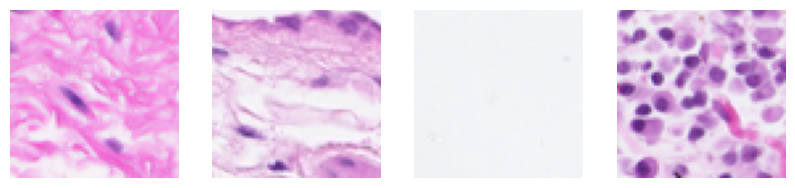

In [14]:
MODE = 'larger'
SEED = 1512
DATA_CONFIG = dict(crop_size=64, batch_size=32)
MODEL_CONFIG = {'width': 64, 'latent_dim': 16, 'levels': 1, 'codebook_size': 256, 'straight_through': True}
# L_codebook = ||sg[z]-e||^2 + beta*||z-sg[e]||^2 (VQ loss of Esser et al., the L_codebook term of the paper's L_D), mean-reduced
CODEBOOK_LOSS = dict(weight=1.0, beta=0.25)
TRAIN_CONFIG = dict(epochs=80, lr=2e-4, rate_weight=1e-3, codebook_loss=CODEBOOK_LOSS,
                    temperature_start=0.05, temperature_end=0.01)     # temperatures overwritten by warm start below
LIMITS = dict(train=1024, val=128, test=256)
TEST_OFFSET = 128     # fixed held-out test crops = shuffled test list [TEST_OFFSET : TEST_OFFSET + LIMITS['test']]
USE_WARM_START = True

seed_everything(SEED)
SPLIT_MANIFEST = OUTPUT_ROOT / 'shared_data_splits.json'
splits = split_images(DATA_ROOT, SPLIT_MANIFEST, seed=SEED)
print('Images per split (full):', {s: len(v) for s, v in splits.items()})

def build_loaders():
    """Train/val loaders with the LIMITS budget; fixed held-out test crops = shuffled test list [TEST_OFFSET : TEST_OFFSET+LIMITS['test']]."""
    ld = make_loaders(splits, seed=SEED, limits=LIMITS, **DATA_CONFIG)
    all_test = make_loaders(splits, seed=SEED, limits=None, **DATA_CONFIG)['test'].dataset.paths
    ld['test'] = DataLoader(ImageDataset(all_test[TEST_OFFSET:TEST_OFFSET + LIMITS['test']], crop_size=DATA_CONFIG['crop_size'], train=False),
                            batch_size=32, shuffle=False)
    return ld

loaders = build_loaders()
assert len(loaders['test'].dataset) == LIMITS['test']
print('Fixed held-out test crops:', len(loaders['test'].dataset))
print('Used for training/validation:', {s: len(loaders[s].dataset) for s in ('train', 'val')})
x = next(iter(loaders['train']))
print('Input batch:', tuple(x.shape))
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, image in zip(axes, x[:4]):
    ax.imshow(image.permute(1, 2, 0)); ax.axis('off')
plt.show()


## 2. Soft vector quantization (student TODO 1-3)

For each latent vector $z_i$ (a row of `flat`) and codeword $e_k$:

$$d_{ik}=\|z_i-e_k\|_2^2=\|z_i\|^2+\|e_k\|^2-2z_i^\top e_k,\qquad
p_{ik}=\frac{\exp(-d_{ik}/\tau)}{\sum_j\exp(-d_{ij}/\tau)},\qquad \widetilde z_i=\sum_k p_{ik}\,e_k .$$

Distances use one matrix product (no `[N,K,D]` tensor). `torch.softmax` subtracts the row maximum internally, so it is numerically stable for the very small temperatures used late in training. Nothing is detached, rounded or arg-min'ed, so gradients reach both the encoder (through $z_i$) and the codebook (through $e_k$).

**Why does small $\tau$ approach nearest-neighbour quantization?** Dividing the (negative) distances by a small $\tau$ magnifies their gaps; the softmax then puts essentially all mass on the closest codeword, $p_{ik}\to\mathbb 1[k=\arg\min_j d_{ij}]$ and $\widetilde z_i\to e_{k^\*}$.
**Large $\tau$?** All $d_{ik}/\tau\to 0$, so $p_{ik}\to 1/K$ and $\widetilde z_i\to$ the mean of the codebook for every input: the assignment carries no information and gradients become tiny/uninformative.
**Why not average indices?** Indices are arbitrary categorical labels: the average of indices 3 and 9 is 6, which points to an unrelated codeword. Averaging codeword *vectors* gives a point in their convex hull, a geometrically meaningful (and differentiable) interpolation.

In [15]:
def soft_quantize(flat, codebook, temperature):
    """
    Args:
        flat: [N, D] latent vectors
        codebook: [K, D] codewords
        temperature: positive scalar

    Returns:
        soft_vectors: [N, D]
        probabilities: [N, K]
    """
    if temperature <= 0:
        raise ValueError("temperature must be positive")

    # TODO 1: squared Euclidean distances [N, K] via ||z||^2 + ||e||^2 - 2 z.e (matrix product, no [N,K,D] tensor)
    distances = (flat.square().sum(-1, keepdim=True)
                 + codebook.square().sum(-1)[None, :]
                 - 2.0 * flat @ codebook.t())

    # TODO 2: soft assignment probabilities [N, K]; normalise over codewords (last dim), numerically stable softmax
    probabilities = torch.softmax(-distances / temperature, dim=-1)

    # TODO 3: weighted codebook vectors [N, D]
    soft_vectors = probabilities @ codebook

    return soft_vectors, probabilities

## 3. Checks: values, temperature limits, gradients, full pipeline

`check_soft_quantize` tests known distances, normalisation, the cold/hot limits and finite-difference gradients (`gradcheck`); `check_pipeline` trains one step of the whole model and round-trips a non-square, non-divisible image through a real bitstream.

In [16]:
check_soft_quantize(soft_quantize)
check_pipeline(soft_quantize)
seed_everything(SEED)
model = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
print('Trainable parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
with torch.no_grad():
    latent = model.encode(x[:1].to(DEVICE))
print('Latent shape:', tuple(latent.shape))
print('Assignment-matrix elements per batch:',
      DATA_CONFIG['batch_size'] * latent.shape[-2] * latent.shape[-1] * MODEL_CONFIG['codebook_size'])

Soft quantization: shape, values, temperature, and gradients passed.
End-to-end gradients and odd-size bitstream round trip passed.
Trainable parameters: 195,987
Latent shape: (1, 16, 32, 32)
Assignment-matrix elements per batch: 8388608


### PSNR and SSIM (student TODO)

Per-image values for RGB tensors in $[0,1]$, averaged equally over images.

$$\mathrm{PSNR}=-10\log_{10}\max(\mathrm{MSE},10^{-12}),\qquad \mathrm{SSIM}=\frac{(2\mu_x\mu_y+C_1)(2\sigma_{xy}+C_2)}{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)},$$

with MSE averaged over channels and pixels of **each image before** the logarithm, an 11x11 Gaussian window ($\sigma=1.5$), $C_1=0.01^2$, $C_2=0.03^2$, population moments per channel, and "valid" convolution (the 5-pixel border is excluded), which equals the TorchMetrics protocol (reflect-pad then crop).

In [17]:
def _metric_inputs(pred, target):
    """Validate matching [B,3,H,W] RGB tensors and compute in float32."""
    if pred.shape != target.shape or pred.ndim != 4 or pred.shape[1] != 3:
        raise ValueError('Expected matching [B,3,H,W] RGB tensors')
    if pred.device != target.device:
        raise ValueError('Prediction and target must be on the same device')
    return pred.float(), target.float()


def psnr_per_image(pred, target):
    """Return [B] PSNR in dB for RGB tensors with data range [0,1].

    Average squared error over channels and pixels independently per image.
    The 1e-12 MSE floor gives 120 dB for identical images.
    """
    pred, target = _metric_inputs(pred, target)
    mse = (pred - target).square().flatten(1).mean(1)
    return -10.0 * torch.log10(mse.clamp_min(1e-12))


def ssim_per_image(pred, target):
    """Return [B] RGB SSIM: Gaussian 11x11, sigma 1.5, data_range=1.

    Population moments are computed independently per channel. Exclude the
    five-pixel border before averaging, matching the TorchMetrics protocol.
    """
    pred, target = _metric_inputs(pred, target)
    if min(pred.shape[-2:]) < 11:
        raise ValueError('SSIM requires images at least 11x11 pixels')
    channels, size, sigma = pred.shape[1], 11, 1.5
    coords = torch.arange(size, device=pred.device, dtype=pred.dtype) - size // 2
    g = torch.exp(-coords.square() / (2 * sigma ** 2))
    g = g / g.sum()
    window = (g[:, None] * g[None, :]).expand(channels, 1, size, size).contiguous()
    blur = lambda t: F.conv2d(t, window, groups=channels)          # 'valid' = border excluded
    mu_x, mu_y = blur(pred), blur(target)
    var_x = blur(pred * pred) - mu_x.square()                       # population (biased) moments
    var_y = blur(target * target) - mu_y.square()
    cov_xy = blur(pred * target) - mu_x * mu_y
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    ssim_map = ((2 * mu_x * mu_y + c1) * (2 * cov_xy + c2)) / \
               ((mu_x.square() + mu_y.square() + c1) * (var_x + var_y + c2))
    return ssim_map.flatten(1).mean(1)

In [18]:
# Reference functions are used only to check the implementation above.
from metrics import ssim_per_image as reference_ssim
import engine as training_engine

metric_generator = torch.Generator().manual_seed(1512)
metric_target = torch.rand(2, 3, 24, 28, generator=metric_generator, device='cpu').to(DEVICE)
metric_pred = (0.8 * metric_target + 0.1).clamp(0, 1)
expected_mse = (metric_pred - metric_target).square().flatten(1).mean(1)
for pred, target in [(metric_target, metric_target), (metric_pred, metric_target),
                     (torch.zeros_like(metric_target), torch.ones_like(metric_target))]:
    actual_psnr = psnr_per_image(pred, target)
    actual_ssim = ssim_per_image(pred, target)
    assert actual_psnr.shape == actual_ssim.shape == (2,)
    assert actual_psnr.device == actual_ssim.device == target.device
    expected_psnr = -10 * (pred - target).square().flatten(1).mean(1).clamp_min(1e-12).log10()
    torch.testing.assert_close(actual_psnr, expected_psnr)
    torch.testing.assert_close(actual_ssim, reference_ssim(pred, target), rtol=1e-4, atol=1e-5)
# Different errors in one batch catch accidentally averaging before log10.
mixed_pred = torch.stack([metric_target[0], metric_pred[1]])
torch.testing.assert_close(psnr_per_image(mixed_pred, metric_target),
                           torch.stack([expected_mse.new_tensor(120.), -10 * expected_mse[1].log10()]))
print('PSNR / SSIM match the closed form and the TorchMetrics reference.')

# Bind the student implementations to all evaluation and training calls below.
student_metrics = dict(psnr_fn=psnr_per_image, ssim_fn=ssim_per_image)
evaluate = partial(training_engine.evaluate, **student_metrics)
fit = partial(training_engine.fit, **student_metrics)

PSNR / SSIM match the closed form and the TorchMetrics reference.


## 4. The rate-distortion objective (as implemented)

Let $r=\mathrm{softmax}(a)$ be the learnable categorical prior over codeword indices ($a$ = `prior_logits`, the entropy model $q_\psi$ of this notebook), $b$ the batch size and $HW$ the number of **input** pixels per image. With $z_i$ the latent vector, $e_{k^\ast}$ the nearest codeword (hard index $k^\ast$) and $p_{ik}$ the soft assignment of Section 2:

$$R_{\text{soft}}=\frac{1}{b\,HW}\sum_{i}\sum_{k}p_{ik}\,\bigl[-\log_2 r_k\bigr],\qquad
L_{\text{codebook}}=\|\mathrm{sg}[z]-e_{k^\ast}\|^2+\beta\,\|z-\mathrm{sg}[e_{k^\ast}]\|^2,$$

$$L=\underbrace{\mathrm{MSE}(x,\hat x)+w_{cb}\,L_{\text{codebook}}}_{\text{distortion } L_D}+\lambda\,\underbrace{R_{\text{soft}}}_{\text{rate (bits/pixel)}} .$$

* **MSE** is measured on $[0,1]$ RGB, so its scale (order $10^{-3}$ to $10^{-4}$) matters when choosing $\lambda$.
* **$L_{\text{codebook}}$** is the vector-quantisation loss that the paper lists inside $L_D$: it moves each codeword toward the latents assigned to it and commits each latent to its codeword. ($\beta=0.25$, $w_{cb}=1$, mean over latent elements.)
* **$R_{\text{soft}}$** is the cross-entropy between the soft assignment and the prior: a *differentiable proxy* for the code length of the indices. It lets the rate gradient reach the encoder, the codebook **and** the prior.
* **$\lambda$** sets the operating point: larger $\lambda$ pushes assignments toward codewords the prior finds cheap, giving more predictable (lower-rate) indices at the cost of fidelity. Section 6-B *measures* how strongly the rate term acts for each $\lambda$ instead of assuming it.
* At validation/test time the rate is evaluated with **hard** indices, $R_{\text{hard}}=\frac1{b\,HW}\sum_i-\log_2 r_{k_i}$, and the checkpoint with the lowest hard validation $\mathrm{MSE}+\lambda R_{\text{hard}}$ is kept (`engine.evaluate`; $L_{\text{codebook}}$ is a training regulariser and is not part of the selection loss). Neither rate number is a measured file size; real bytes are measured in Section 6-A.

The temperature decays geometrically from $\tau_{\text{start}}$ to $\tau_{\text{end}}$; the total gradient norm is clipped to 1; Adam optimises encoder, decoder, codebook and prior jointly.

**Which parameters get gradients?** Reconstruction: decoder, codebook and (through the soft/straight-through path) encoder. $L_{\text{codebook}}$: encoder and codebook. Rate: encoder and codebook (through $d_{ik}$ inside $p_{ik}$) and the prior $a$; the decoder receives none. **Why can soft training quality differ from hard evaluation quality?** The decoder is trained on soft mixtures (or hard-forward/soft-backward vectors) but evaluated on exact codewords; the gap closes as $\tau\to0$. **Collapsed codebook:** only a handful of codewords are ever selected (low perplexity, one spike in the usage histogram, a very peaked prior), giving near-zero rate but blurry reconstructions.


## 4a. What is reproduced from RDVQ, and in which form

| Piece | RDVQ paper | Implemented here |
|---|---|---|
| Relaxed rate | $R_{\text{soft}}=\mathbb E_{b,l}\bigl[-\sum_k p_{\text{soft}}(b,l,k)\log q_\psi(b,l,k)\bigr]$ (Eq. 7), $p_{\text{soft}}=\mathrm{softmax}_k(-d_{b,l,k}/\tau)$ | **Same $p_{\text{soft}}$ and the same cross-entropy form.** |
| Entropy model $q_\psi(b,l,k)$ | conditional on preceding tokens (masked Transformer) | $q_\psi(b,l,k)=r_k=\mathrm{softmax}(a)_k$: the **context-free (zeroth-order) special case of Eq. 7**, one learnable categorical prior shared by all positions. This is what the course helper `CompressionModel` computes; Lecture 11's statement that a simplified version replaces the entropy model is read here as this substitution (a learnable prior in place of $q_\psi$). It is *not* read as $R=-\sum_k p_{\text{soft}}\log p_{\text{soft}}$, which has no learnable index-frequency model and is not what the provided rate branch computes. |
| Distortion $L_D$ | $L_{\text{codebook}}+L_{\text{MSE}}+L_{\text{LPIPS}}+0.1\,L_{\text{GAN}}$ | $L_{\text{codebook}}$ (VQ loss, $\beta=0.25$) $+$ MSE. LPIPS and GAN need a pretrained network and a discriminator and are not in the lecture's $L=\text{MSE}+\lambda L_R$; they are not used. |
| Reconstruction path | hard quantised embeddings $y_q$; relaxation only in the rate branch | default model: straight-through (hard forward, soft backward), i.e. the decoder sees hard codewords; a fully-soft decoder input is trained only as the comparison in 6-C. |
| Codebook / stages | codebook pretrained in stage 1 and then frozen; entropy model pretrained in stage 2; joint RD in stage 3 | AE warm-up and k-means initialisation on training crops, then **one joint stage** in which the codebook is trained (not frozen) together with encoder, decoder and prior. |
| Scale | three scales, 4096 x 32 codebook, ImageNet/OpenImage/DF2K | single scale, 256 x 16 codebook, 1024 training crops of 64x64 (Section 7). |

**Consequence for the rate that is optimised.** Because $q_\psi$ here has no context, the optimised rate $R_{\text{hard}}$ is a zeroth-order index cost. The stored file is produced by zlib on the packed indices (provided `codec.py`), which also exploits spatial repetition in the index map, so *optimised* and *stored* rates differ. Sections 6-A and 6-B print both numbers for every model that is trained.

The code cell below subclasses `CompressionModel` **inside the notebook** (no helper file is edited): it has identical parameters, config and bitstream, and its `forward` additionally returns the latent vectors and the selected codewords, which `rdvq_loss` needs for $L_{\text{codebook}}$. The checks at the end of the cell run before any training.


In [19]:
class RDVQModel(CompressionModel):
    """CompressionModel with the same parameters/config/bitstream; forward also returns the flat latents and selected codewords."""
    def forward(self, x, temperature=0.5):
        captured = {}
        handle = self.encoder.register_forward_hook(lambda module, inputs, output: captured.__setitem__('z', output))
        try:
            out = super().forward(x, temperature)
        finally:
            handle.remove()
        z = captured['z']
        out['latent'] = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
        out['selected'] = F.embedding(out['indices'].reshape(-1), self.codebook)
        return out


def rdvq_loss(result, x, rate_weight):
    """L = MSE + w_cb * L_codebook + lambda * R_soft (training objective of Section 4)."""
    mse = (result['reconstruction'] - x).square().mean()
    z, e = result['latent'], result['selected']
    l_codebook = F.mse_loss(e, z.detach()) + CODEBOOK_LOSS['beta'] * F.mse_loss(z, e.detach())
    return mse + CODEBOOK_LOSS['weight'] * l_codebook + rate_weight * result['estimated_bpp']


# every fit() call below (main run, lambda sweep, quantisation comparison) now trains with rdvq_loss
fit = partial(training_engine.fit, loss_fn=rdvq_loss, **student_metrics)


def check_rdvq_objective():
    torch.manual_seed(0)
    xt = torch.rand(4, 3, 64, 64, device=DEVICE)
    base = CompressionModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    sub = RDVQModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    sub.load_state_dict(base.state_dict())
    for training in (True, False):                     # subclass must not change reconstruction or rate
        base.train(training); sub.train(training)
        a, b = base(xt, temperature=0.05), sub(xt, temperature=0.05)
        torch.testing.assert_close(a['reconstruction'], b['reconstruction'])
        torch.testing.assert_close(a['estimated_bpp'], b['estimated_bpp'])
    n_tokens = 4 * (64 // sub.factor) ** 2
    assert b['latent'].shape == (n_tokens, MODEL_CONFIG['latent_dim']) == tuple(b['selected'].shape)
    sub.train(); sub.zero_grad()
    loss = rdvq_loss(sub(xt, temperature=0.05), xt, 1e-3)
    assert torch.isfinite(loss)
    loss.backward()
    for name, params in [('encoder', sub.encoder.parameters()), ('decoder', sub.decoder.parameters()),
                         ('codebook', [sub.codebook]), ('prior', [sub.prior_logits])]:
        grads = [p.grad for p in params]
        assert all(g is not None and torch.isfinite(g).all() for g in grads) and sum(g.abs().sum().item() for g in grads) > 0, name
    print('RDVQModel / rdvq_loss: identical forward to CompressionModel, finite loss, gradients reach encoder, decoder, codebook and prior.')

check_rdvq_objective()


RDVQModel / rdvq_loss: identical forward to CompressionModel, finite loss, gradients reach encoder, decoder, codebook and prior.


## 5. Train the model

Warm start (training images only): 8 epochs of continuous autoencoding, then k-means initialisation of the codewords; the temperature schedule is set from the median nearest-codeword distance. Then joint training with `fit` (Adam, lr 2e-4, 80 epochs) on `rdvq_loss` = MSE + codebook loss + $\lambda R_{\text{soft}}$. The reported model uses $\lambda=10^{-3}$: at $\lambda=10^{-4}$ the rate term supplied only a small fraction of the encoder gradient. Section 6-B prints the measured gradient share, prior entropy, estimated rate and stored rate for $\lambda\in\{10^{-4},10^{-3},10^{-2}\}$.

In [20]:
import csv
REUSE_CHECKPOINT = None   # optional path to a finished run's best.pt; None trains from scratch
seed_everything(SEED)
loaders = build_loaders()

if REUSE_CHECKPOINT is None:
    RUN_DIR = OUTPUT_ROOT / ('solution_' + MODE + '_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    model = RDVQModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
    initialization = None
    if USE_WARM_START:
        initialization = warm_start(model, loaders['train'], DEVICE, epochs=8, max_vectors=32768)
        TRAIN_CONFIG.update(temperature_start=initialization['temperature_start'],
                            temperature_end=initialization['temperature_start'] * 0.2)
        print('Training-only initialization:', initialization)
    t0 = time.time()
    model, history = fit(model, loaders, TRAIN_CONFIG, RUN_DIR, DEVICE)
    print(f'Training time: {(time.time() - t0) / 60:.1f} min')
    if initialization is not None:
        (RUN_DIR / 'warmup.json').write_text(json.dumps(initialization, indent=2))
else:
    RUN_DIR = Path(REUSE_CHECKPOINT).resolve().parent
    model, saved = load_checkpoint(REUSE_CHECKPOINT, soft_quantize, DEVICE)
    assert model.config == MODEL_CONFIG, 'Reuse a checkpoint with the displayed architecture'
    TRAIN_CONFIG = saved['train_config']
    with (RUN_DIR / 'history.csv').open() as handle:
        history = [{k: float(v) for k, v in row.items()} for row in csv.DictReader(handle)]
    print('Loaded completed run:', REUSE_CHECKPOINT)

protocol = dict(seed=SEED, mode=MODE, data_root=str(DATA_ROOT.resolve()), manifest=str(SPLIT_MANIFEST.resolve()),
                data_config=DATA_CONFIG, limits=LIMITS, test_offset=TEST_OFFSET, codebook_loss=CODEBOOK_LOSS,
                used_paths={s: [str(p.relative_to(DATA_ROOT)) for p in l.dataset.paths] for s, l in loaders.items()})
(RUN_DIR / 'data_protocol.json').write_text(json.dumps(protocol, indent=2))
print('Saved:', RUN_DIR)

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Training-only initialization: {'warmup_epochs': 8, 'warmup_seconds': 41.17310000400016, 'training_mse': [0.03651406627614051, 0.010660803862265311, 0.006725735904183239, 0.0035484740146785043, 0.00246359874290647, 0.0023256804306583945, 0.002074186566460412, 0.00187922221084591], 'initialization_vectors': 32768, 'temperature_start': 0.02934122271835804, 'temperature_end': 0.0029341222718358042}
Epoch 1/80: train=0.00703, hard val PSNR=27.71, SSIM=0.8643, estimated bpp=1.9992
Epoch 2/80: train=0.00565, hard val PSNR=28.16, SSIM=0.8662, estimated bpp=1.9981
Epoch 3/80: train=0.00540, hard val PSNR=28.34, SSIM=0.8693, estimated bpp=1.9968
Epoc

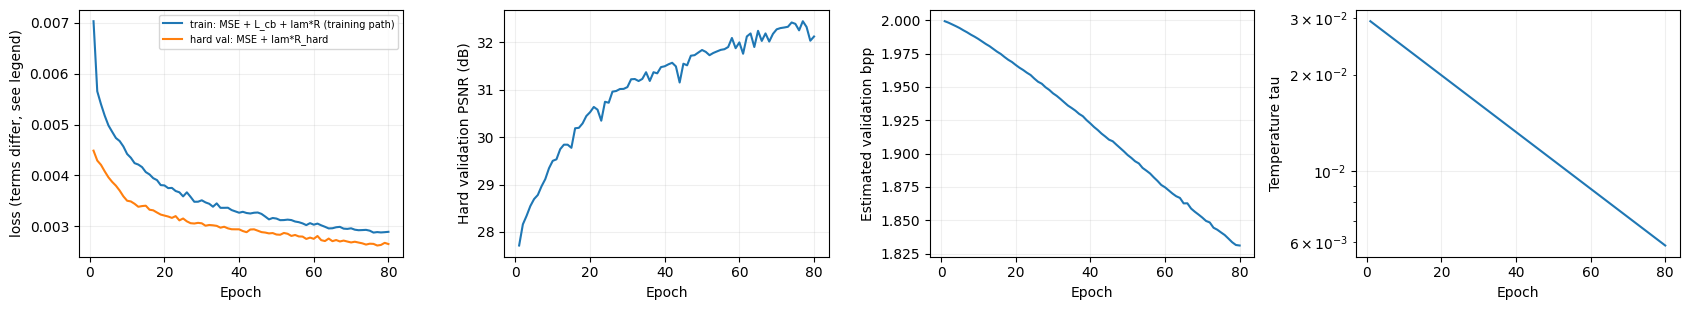

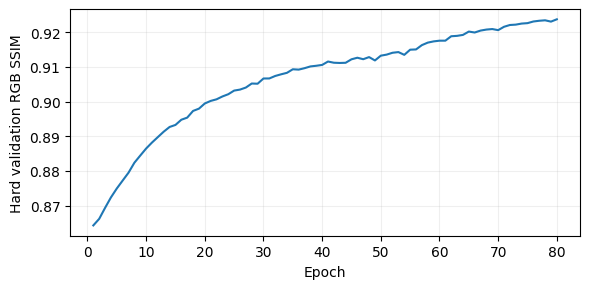

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
epochs = [r['epoch'] for r in history]
axes[0].plot(epochs, [r['train_loss'] for r in history], label='train: MSE + L_cb + lam*R (training path)')
axes[0].plot(epochs, [r['val_loss'] for r in history], label='hard val: MSE + lam*R_hard')
axes[0].set_ylabel('loss (terms differ, see legend)'); axes[0].legend(fontsize=7)
axes[1].plot(epochs, [r['val_psnr'] for r in history]); axes[1].set_ylabel('Hard validation PSNR (dB)')
axes[2].plot(epochs, [r['val_estimated_bpp'] for r in history]); axes[2].set_ylabel('Estimated validation bpp')
axes[3].plot(epochs, [r['temperature'] for r in history]); axes[3].set_ylabel('Temperature tau'); axes[3].set_yscale('log')
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()
if all('val_ssim' in row for row in history):
    plt.figure(figsize=(6, 3))
    plt.plot(epochs, [row['val_ssim'] for row in history])
    plt.xlabel('Epoch'); plt.ylabel('Hard validation RGB SSIM'); plt.grid(alpha=.2)
    plt.tight_layout(); plt.savefig(RUN_DIR / 'validation_ssim.png', dpi=160); plt.show()

## 6. Part 3 analysis

### 6-A. Architecture, codebook and the latent -> integer-index path  *(12 pts)*

The cell prints the exact layer structure and parameter counts, follows one image through the chain
`image -> encoder -> latent vectors z -> nearest codeword (argmin) -> integer index map -> bitstream -> indices -> codeword lookup -> decoder`, checks that decoding the stored indices reproduces the model output exactly, and reports four different "bits per pixel" numbers so that rate accounting is explicit:
(1) fixed-length $\lceil\log_2K\rceil$ bits/index, (2) the model's estimated rate $R_{\text{hard}}$ from the learned prior, (3) the zero-order empirical entropy of the validation indices, (4) the **measured** payload of the saved bitstream (zlib). Header and shared checkpoint bytes are excluded from bpp.

**Rate accounting.** The cell prints, for the saved run, the fixed-length rate, the training objective's estimate $R_{\text{hard}}$, the zero-order entropy of the validation indices and the measured zlib payload of real bitstreams, together with their ratio ("Rate-gap summary"). $R_{\text{hard}}$ is a cross-entropy under one context-free learned prior (Section 4a), whereas the stored payload comes from zlib, which also exploits spatial repetition in the index map. The *optimised* rate and the *stored* rate therefore differ; the printed ratio gives the size of the difference for this run, and the file sizes used for evaluation are the measured ones. No rate value is quoted in this text: every number is printed by the code.


CompressionModel(
  (encoder): Encoder(
    (net): Sequential(
      (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): SiLU()
      (2): ResidualBlock(
        (net): Sequential(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): SiLU()
          (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
      )
      (3): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1))
      (1): ResidualBlock(
        (net): Sequential(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): SiLU()
          (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
      )
      (2): Upsample(scale_factor=2.0, mode='nearest')
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): SiLU()
      (

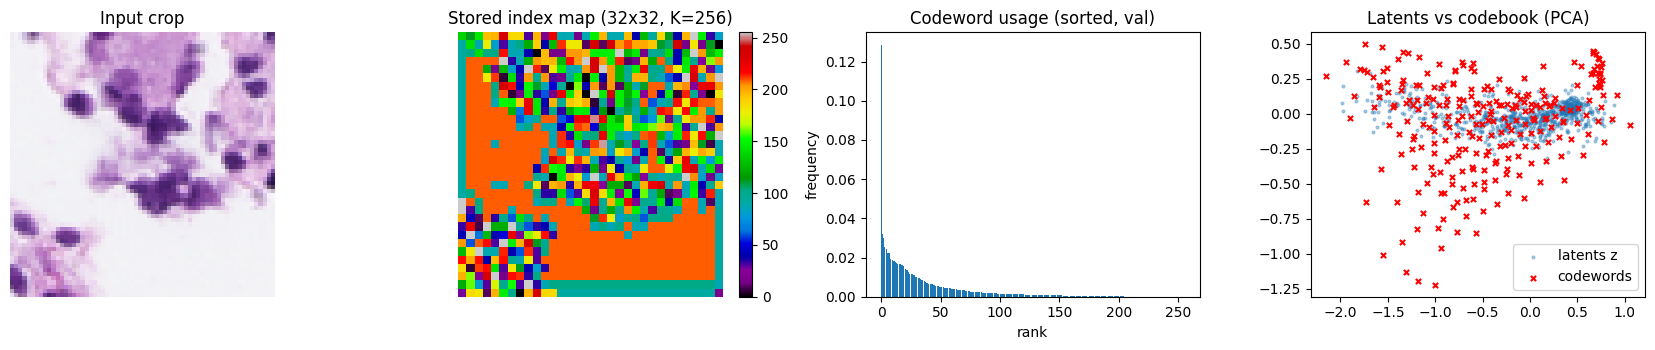

In [22]:
model, ckpt = load_checkpoint(RUN_DIR / 'best.pt', soft_quantize, DEVICE)     # hard-evaluation model
print(model, '\n')
K, D, factor = model.config['codebook_size'], model.config['latent_dim'], model.factor
crop = DATA_CONFIG['crop_size']
zh = zw = math.ceil(crop / factor)
idx_bits = math.ceil(math.log2(K))
n_enc = sum(p.numel() for p in model.encoder.parameters())
n_dec = sum(p.numel() for p in model.decoder.parameters())
n_cb, n_prior = model.codebook.numel(), model.prior_logits.numel()
print(f'Parameters: encoder {n_enc:,} | decoder {n_dec:,} | codebook {n_cb:,} ({K} x {D}) | prior {n_prior:,} '
      f'| total {n_enc + n_dec + n_cb + n_prior:,}')
print(f'Input {crop}x{crop}x3 -> latent {D} x {zh} x {zw} ({zh * zw} tokens), downsampling factor {factor}')
print(f'Codebook K={K}: {idx_bits} bits per index -> fixed-length rate {zh * zw * idx_bits / crop ** 2:.3f} bpp')

xb = next(iter(loaders['test']))[:1].to(DEVICE)
with torch.no_grad():
    z = model.encode(xb)                                         # [1, D, zh, zw]
    flat = z.permute(0, 2, 3, 1).reshape(-1, D)                  # [zh*zw, D]
    idx = model.hard_indices(flat)                               # [zh*zw] integers in [0, K)
    exact = (flat[:, None, :] - model.codebook[None]).square().sum(-1)      # exact distances [zh*zw, K]
    agree = (exact.argmin(-1) == idx).float().mean().item()
    assert agree > 0.99, agree
    index_map = idx.reshape(1, zh, zw)
    rec_idx = model.decode_indices(index_map, crop, crop)        # decoder fed ONLY the stored integers
    rec_fwd = model(xb)['reconstruction']
print(f'argmin agreement with exact distances: {agree:.4f}')
print('max |decode_indices(indices) - model(x)| =', (rec_idx - rec_fwd).abs().max().item())
print('first 8x8 block of the index map:\n', index_map[0, :8, :8].cpu().numpy())
for t in range(3):
    print(f'token {t}: z[:4]={flat[t, :4].cpu().numpy().round(3)} -> index {idx[t].item()}, '
          f'||z-e||^2={exact[t, idx[t]].item():.4f}')

# real bitstream round trip on 32 held-out crops (index-decoding check)
worst, bpps = 0.0, []
for xi in next(iter(loaders['test']))[:32]:
    xi = xi[None].to(DEVICE)
    stream = compress(model, xi)
    out = decompress(model, stream)
    ref = model(xi)['reconstruction']
    worst = max(worst, (out - ref).abs().max().item())
    bpps.append(8 * payload_size(stream) / crop ** 2)
print(f'bitstream round trip (32 crops): max |decoded - model output| = {worst:.2e}')
assert worst < 1e-4

# rate accounting over the validation crops
counts = torch.zeros(K)
with torch.no_grad():
    for xv in loaders['val']:
        counts += torch.bincount(model(xv.to(DEVICE))['indices'].flatten().cpu(), minlength=K).float()
pr = counts / counts.sum()
H = -(pr[pr > 0] * pr[pr > 0].log2()).sum().item()
est = evaluate(model, loaders['val'], DEVICE, ckpt['train_config']['rate_weight'])
print('\nRate accounting (bits per input pixel):')
print(f'  fixed-length indices           : {zh * zw * idx_bits / crop ** 2:.4f}')
print(f'  estimated R_hard (learned prior): {est["estimated_bpp"]:.4f}')
print(f'  empirical zero-order entropy    : {H * zh * zw / crop ** 2:.4f}   ({H:.2f} bits/index)')
print(f'  measured zlib payload (test)    : {np.mean(bpps):.4f}')
print(f'Codewords used on validation: {int((counts > 0).sum())}/{K} | perplexity 2^H = {2 ** H:.1f}')
print(f'Validation (hard): PSNR {est["psnr"]:.2f} dB | SSIM {est["ssim"]:.4f}')
print('\nRate-gap summary (bits per input pixel):')
print(f'  training objective R_hard, val      : {est["estimated_bpp"]:.4f}  (what the loss optimises)')
print(f'  zlib payload, 32 test crops         : {np.mean(bpps):.4f}  (coded latent size)')
print(f'  training estimate over zlib payload : {est["estimated_bpp"] / np.mean(bpps) - 1:+.1%}')
print('  Section 9 DNN bpp, 256 test crops    : see comparison summary (different crop set)')

# figure: index map, usage histogram, latent vs codebook (2-D PCA)
mu = flat.mean(0, keepdim=True)
_, _, Vh = torch.linalg.svd(flat - mu, full_matrices=False)
proj = lambda m: ((m - mu) @ Vh[:2].T).cpu()
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].imshow(xb[0].cpu().permute(1, 2, 0)); ax[0].set_title('Input crop'); ax[0].axis('off')
im = ax[1].imshow(index_map[0].cpu(), cmap='nipy_spectral'); ax[1].set_title(f'Stored index map ({zh}x{zw}, K={K})')
ax[1].axis('off'); plt.colorbar(im, ax=ax[1], fraction=.046)
ax[2].bar(range(K), counts.sort(descending=True).values / counts.sum())
ax[2].set_title('Codeword usage (sorted, val)'); ax[2].set_xlabel('rank'); ax[2].set_ylabel('frequency')
pf, pc = proj(flat), proj(model.codebook.detach())
ax[3].scatter(pf[:, 0], pf[:, 1], s=4, alpha=.35, label='latents z'); ax[3].scatter(pc[:, 0], pc[:, 1], s=14, marker='x', c='r', label='codewords')
ax[3].set_title('Latents vs codebook (PCA)'); ax[3].legend(); plt.tight_layout()
plt.savefig(RUN_DIR / 'part3_architecture_index.png', dpi=160); plt.show()

### 6-B. Measured terms of the rate-distortion objective  *(8 pts)*

The same checkpoint is evaluated on the validation crops twice: with the **hard** evaluation path, and with the **training** path (`model.train()` switches only the quantizer branch; the network has no dropout or batch-norm) at $\tau_{\text{end}}$ and $\tau_{\text{start}}$. For each we print $\mathrm{MSE}$, the weighted codebook term, $R$, $\lambda R$ and the totals, so every term of the objective is visible with its actual magnitude. With `straight_through=True` the decoder always sees hard vectors in the forward pass, so the soft/hard difference shows up mainly in the **rate** term.

**What the rate term does.** The cell after the table does not assume the rate term is active; it measures, for the reported $\lambda$ and for a $\lambda$ sweep (two extra 80-epoch runs): (i) the encoder-gradient share $\lambda\|\nabla_{\text{enc}}R_{\text{soft}}\|/\|\nabla_{\text{enc}}\mathrm{MSE}\|$; (ii) the prior's entropy relative to the uniform value $\log_2K$; (iii) how far the validation rate moved during training; (iv) the optimised rate $R_{\text{hard}}$ against the stored rate (measured zlib payload on the same validation crops). All numbers are printed by the code; none are quoted in this text.


lambda = 0.001, w_cb = 1, beta = 0.25   (validation crops, selected checkpoint, epoch 77)
path                                MSE  PSNR dB  R (bpp)      lam*R     w*L_cb    L(sel.)    L_total  lam*R/L_total
hard (evaluation)             7.894e-04    32.44   1.8363  1.836e-03  4.052e-04  2.626e-03  3.031e-03  60.6%
soft, tau_end=0.005868        7.894e-04    32.44   1.8435  1.844e-03  4.052e-04  2.633e-03  3.038e-03  60.7%
soft, tau_start=0.02934       7.894e-04    32.44   1.8882  1.888e-03  4.052e-04  2.678e-03  3.083e-03  61.3%


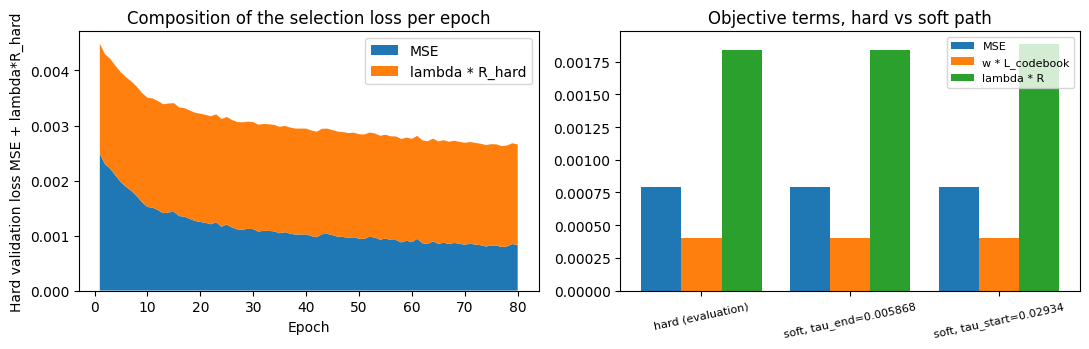

In [23]:
lam = ckpt['train_config']['rate_weight']
cb_cfg = ckpt['train_config'].get('codebook_loss', CODEBOOK_LOSS)
tau_start, tau_end = ckpt['train_config']['temperature_start'], ckpt['train_config']['temperature_end']

@torch.no_grad()
def objective_terms(net, loader, mode, tau=None, lam=lam):
    """mode='hard': evaluation path. mode='soft': training path (soft_quantize in the rate branch)."""
    net.train(mode == 'soft')
    tot, n = dict(mse=0., psnr=0., rate=0., cb=0.), 0
    for xx in loader:
        xx = xx.to(DEVICE)
        out = net(xx, temperature=tau) if mode == 'soft' else net(xx)
        b = len(xx)
        tot['mse'] += (out['reconstruction'] - xx).square().flatten(1).mean(1).sum().item()
        tot['psnr'] += psnr_per_image(out['reconstruction'], xx).sum().item()
        tot['rate'] += out['estimated_bpp'].item() * b
        zz = net.encode(xx); fl = zz.permute(0, 2, 3, 1).reshape(-1, zz.shape[1])
        ee = F.embedding(net.hard_indices(fl), net.codebook)
        tot['cb'] += ((1 + cb_cfg['beta']) * F.mse_loss(ee, fl)).item() * b      # value of L_codebook (both terms have equal value)
        n += b
    net.eval()
    r = {k: v / n for k, v in tot.items()}
    r['w*L_cb'] = cb_cfg['weight'] * r['cb']
    r['lam*R'] = lam * r['rate']
    r['L'] = r['mse'] + r['lam*R']                 # validation / checkpoint-selection loss of engine.evaluate
    r['L_total'] = r['L'] + r['w*L_cb']            # full training objective, evaluated as a value
    return r

rows = {'hard (evaluation)': objective_terms(model, loaders['val'], 'hard'),
        f'soft, tau_end={tau_end:.4g}': objective_terms(model, loaders['val'], 'soft', tau_end),
        f'soft, tau_start={tau_start:.4g}': objective_terms(model, loaders['val'], 'soft', tau_start)}
print(f'lambda = {lam:g}, w_cb = {cb_cfg["weight"]:g}, beta = {cb_cfg["beta"]:g}   (validation crops, selected checkpoint, epoch {ckpt["epoch"]})')
print(f'{"path":28s} {"MSE":>10s} {"PSNR dB":>8s} {"R (bpp)":>8s} {"lam*R":>10s} {"w*L_cb":>10s} {"L(sel.)":>10s} {"L_total":>10s}  lam*R/L_total')
for name, r in rows.items():
    print(f'{name:28s} {r["mse"]:10.3e} {r["psnr"]:8.2f} {r["rate"]:8.4f} {r["lam*R"]:10.3e} {r["w*L_cb"]:10.3e} {r["L"]:10.3e} {r["L_total"]:10.3e}  {r["lam*R"] / r["L_total"]:.1%}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ep = [r['epoch'] for r in history]
vm = np.array([r['val_mse'] for r in history]); vr = np.array([r['val_estimated_bpp'] for r in history]) * lam
ax[0].stackplot(ep, vm, vr, labels=['MSE', 'lambda * R_hard']); ax[0].legend(loc='upper right')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Hard validation loss MSE + lambda*R_hard'); ax[0].set_title('Composition of the selection loss per epoch')
names = list(rows); w = .27
ax[1].bar(np.arange(len(names)) - w, [rows[n]['mse'] for n in names], w, label='MSE')
ax[1].bar(np.arange(len(names)), [rows[n]['w*L_cb'] for n in names], w, label='w * L_codebook')
ax[1].bar(np.arange(len(names)) + w, [rows[n]['lam*R'] for n in names], w, label='lambda * R')
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(names, rotation=12, fontsize=8); ax[1].legend(fontsize=8)
ax[1].set_title('Objective terms, hard vs soft path'); plt.tight_layout()
plt.savefig(RUN_DIR / 'part3_objective_terms.png', dpi=160); plt.show()


In [24]:
# ---- Rate-term diagnostics and rate-weight sweep -----------------------------------------
main_lam = float(ckpt['train_config']['rate_weight'])
with torch.no_grad():
    log_p = F.log_softmax(model.prior_logits.detach().cpu().double(), dim=0)   # natural-log probabilities
    log2_prior = log_p / math.log(2)
    prior_entropy = float(-(log_p.exp() * log2_prior).sum())        # bits/index implied by the prior alone
    uniform_bits = math.log2(K)                                     # 8 bits for K=256
    ce_learned = float(-(pr.double() * log2_prior).sum())           # validation index histogram under the prior
tokens_per_pixel = zh * zw / crop ** 2
print(f'Prior entropy            : {prior_entropy:.3f} bits/index (uniform {uniform_bits:.3f})')
print(f'Validation cross-entropy : {ce_learned:.3f} bits/index under the learned prior')
print(f'Zero-order entropy       : {H:.3f} bits/index (memoryless-coder bound on these indices)')
print(f'Rate saved by the prior  : {uniform_bits - ce_learned:.3f} bits/index '
      f'= {(uniform_bits - ce_learned) * tokens_per_pixel:.4f} bpp')
r_first, r_last = history[0]['val_estimated_bpp'], history[-1]['val_estimated_bpp']
print(f'Validation rate over training: epoch 1 {r_first:.4f} -> epoch {history[-1]["epoch"]:.0f} '
      f'{r_last:.4f} bpp ({(r_last - r_first) / r_first:+.1%})')


def rate_grad_share(net, lam_, tau_, loader):
    """lambda*||dR_soft/d encoder|| / ||dMSE/d encoder|| on the first validation batch (training path, deterministic crops)."""
    probe_net = copy.deepcopy(net).train()
    xb_ = next(iter(loader))[:8].to(DEVICE)
    def enc_grad_norm(scalar_fn):
        probe_net.zero_grad(set_to_none=True)
        scalar_fn().backward()
        parts = [p.grad.square().sum() for p in probe_net.encoder.parameters() if p.grad is not None]
        return float(torch.stack(parts).sum().sqrt()) if parts else float('nan')
    g_mse = enc_grad_norm(lambda: (probe_net(xb_, temperature=tau_)['reconstruction'] - xb_).square().mean())
    g_rate = enc_grad_norm(lambda: probe_net(xb_, temperature=tau_)['estimated_bpp'])
    return lam_ * g_rate / g_mse


def measured_zlib_bpp(net, loader):
    """Stored rate: real compress() bitstreams, latent payload bytes only (same convention as Section 9)."""
    total_bytes, total_pixels = 0, 0
    for xb_ in loader:
        for xi_ in xb_:
            xi_ = xi_[None].to(DEVICE)
            total_bytes += payload_size(compress(net, xi_))
            total_pixels += xi_.shape[-2] * xi_.shape[-1]
    return 8 * total_bytes / total_pixels


RUN_RATE_SWEEP = True    # two extra 80-epoch runs (about 15 min on a T4): the lambda values other than the reported one
SWEEP_LAMBDAS = [l_ for l_ in (1e-4, 1e-3, 1e-2) if not math.isclose(l_, main_lam)]
rate_runs = {}
if RUN_RATE_SWEEP:
    for rw in SWEEP_LAMBDAS:
        seed_everything(SEED)
        sw_loaders = build_loaders()
        cand = RDVQModel(soft_quantize, **MODEL_CONFIG).to(DEVICE)
        cfg = dict(TRAIN_CONFIG, rate_weight=rw)
        init = warm_start(cand, sw_loaders['train'], DEVICE, epochs=8, max_vectors=32768)
        cfg.update(temperature_start=init['temperature_start'], temperature_end=init['temperature_start'] * 0.2)
        dest = OUTPUT_ROOT / (f'rate_lam{rw:g}_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
        cand, _ = fit(cand, sw_loaders, cfg, dest, DEVICE)
        v = evaluate(cand, sw_loaders['val'], DEVICE, rw)
        rate_runs[rw] = dict(mse=v['mse'], psnr=v['psnr'], ssim=v['ssim'], bpp=v['estimated_bpp'],
                             zlib=measured_zlib_bpp(cand, sw_loaders['val']),
                             gshare=rate_grad_share(cand, rw, cfg['temperature_end'], sw_loaders['val']))
        del cand
# Reference row: the reported (main) run, read from the selected checkpoint
v_main = ckpt['validation']
rate_runs[main_lam] = dict(mse=v_main['mse'], psnr=v_main['psnr'], ssim=v_main['ssim'], bpp=v_main['estimated_bpp'],
                           zlib=measured_zlib_bpp(model, loaders['val']),
                           gshare=rate_grad_share(model, main_lam, tau_end, loaders['val']))
print(f'\n{"lambda":>8s} {"val PSNR":>9s} {"val SSIM":>9s} {"R_hard bpp":>11s} {"zlib bpp":>9s} {"R/zlib":>7s} {"lam*R share":>12s} {"enc-grad share":>15s}')
for rw in sorted(rate_runs):
    r = rate_runs[rw]
    share = rw * r['bpp'] / (r['mse'] + rw * r['bpp'])
    print(f'{rw:8g} {r["psnr"]:9.2f} {r["ssim"]:9.4f} {r["bpp"]:11.4f} {r["zlib"]:9.4f} {r["bpp"] / r["zlib"]:7.2f} {share:12.1%} {r["gshare"]:15.1%}')
print('(R_hard: rate the objective optimises, context-free prior. zlib: stored rate, measured on the same validation crops.)')
(RUN_DIR / 'rate_sweep.json').write_text(json.dumps({f'{k:g}': v for k, v in sorted(rate_runs.items())}, indent=2))

m = rate_runs[main_lam]
print(f'\nRate-term activity of the reported model (lambda={main_lam:g}):')
print(f'  encoder-gradient share lambda*||dR_soft/dEnc|| / ||dMSE/dEnc|| = {m["gshare"]:.1%}')
print(f'  prior entropy {prior_entropy:.3f} vs uniform {uniform_bits:.3f} bits/index; validation rate {r_first:.4f} -> {r_last:.4f} bpp ({(r_last - r_first) / r_first:+.1%})')
print(f'  optimised rate R_hard {m["bpp"]:.4f} bpp vs stored rate (measured zlib payload) {m["zlib"]:.4f} bpp on the same validation crops')


Prior entropy            : 7.895 bits/index (uniform 8.000)
Validation cross-entropy : 7.345 bits/index under the learned prior
Zero-order entropy       : 6.315 bits/index (memoryless-coder bound on these indices)
Rate saved by the prior  : 0.655 bits/index = 0.1637 bpp
Validation rate over training: epoch 1 1.9992 -> epoch 80 1.8311 bpp (-8.4%)
Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00523, hard val PSNR=27.71, SSIM=0.8643, estimated bpp=1.9993
Epoch 2/80: train=0.00385, hard val PSNR=28.16, SSIM=0.8662, estimated bpp=1.9983
Epoch 3/80: train=0.00360, hard val PSNR=28.34, SSIM=0.8694, estimated bpp=1.9970
Epoch 4/80: train=0.00338, hard val PSNR=28.55, SSIM=0

### 6-C. Soft quantization (training) vs hard assignment (evaluation)  *(10 pts)*

1. **Gradient path.** The hard path $\arg\min_k d_{ik}$ is piecewise constant, so no gradient reaches the encoder; the soft path does. The cell backpropagates four scalars and prints the encoder gradient norm for each.
2. **Temperature sweep.** For a grid of $\tau$ we measure, on validation crops, how far the soft vector is from the chosen codeword, how confident the assignment is, the soft rate $R_{\text{soft}}(\tau)$ vs the hard rate, and the PSNR when the decoder is fed soft vs hard vectors. This quantifies the training-evaluation discrepancy and shows how the schedule $\tau_{\text{start}}\to\tau_{\text{end}}$ (and, optionally, the straight-through estimator) addresses it.

**Results.** The code cells below print them: the straight-through forward pass uses the hard codewords, so its PSNR gap is 0 by construction (the check cell verifies this numerically, and also the soft-hard distance the rate branch still sees); the evidence about the discrepancy is the fully-soft run, whose hard-evaluation PSNR is compared with its soft-path PSNR in the quantisation-strategy cell. Straight-through still leaves a gap in the rate path ($R_{\text{soft}}$ against $R_{\text{hard}}$ at $\tau_{\text{end}}$, printed in 6-B and in the strategy cell). Each strategy is trained with one seed, so the fully-soft gap is a single-run measurement. No figure is quoted in this text.


hard MSE   -> encoder      None (no gradient path)
hard rate  -> encoder      None (no gradient path)
soft MSE   -> encoder      1.641e-02
soft rate  -> encoder      1.128e+00
soft rate  -> decoder      None (no gradient path)
Weighted encoder gradient, lambda*rate / MSE (lambda=0.001): 6.87%
       tau  ||soft-hard||^2  mean max p   R_soft   R_hard  PSNR soft  PSNR hard
 0.0005868       2.1465e-04       0.944   1.8364   1.8363      32.59      32.44
  0.002934       1.0860e-03       0.710   1.8384   1.8363      32.98      32.44
  0.005868       1.8152e-03       0.494   1.8435   1.8363      33.06      32.44
   0.02934       3.6389e-03       0.135   1.8882   1.8363      32.27      32.44
    0.1467       1.0715e-02       0.034   1.9521   1.8363      29.32      32.44
    0.7335       7.3803e-02       0.010   1.9914   1.8363      21.50      32.44
     2.934       2.5429e-01       0.005   2.0115   1.8363      15.70      32.44


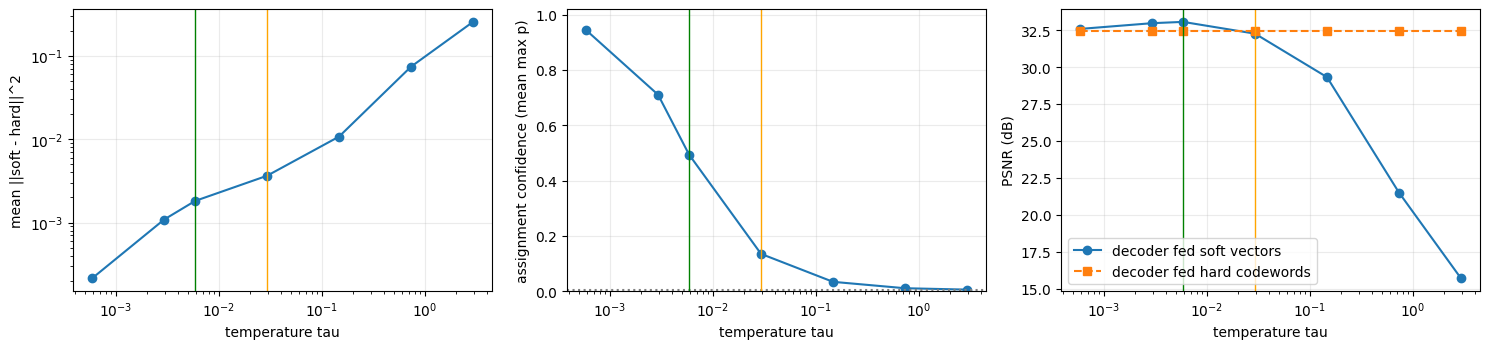

In [25]:
# ---- (1) which scalar can send gradient to the encoder? -------------------------------------
xg = next(iter(loaders['train']))[:8].to(DEVICE)
def encoder_grad_norm(net, scalar_fn):
    net.zero_grad(set_to_none=True)
    scalar = scalar_fn()
    scalar.backward()
    grads = [p.grad for p in net.encoder.parameters()]
    if all(g is None for g in grads):
        return None
    return float(torch.sqrt(sum(g.square().sum() for g in grads if g is not None)))

probe = {}
net = copy.deepcopy(model)
net.eval()                                                                  # hard path
out_h = lambda: net(xg)
probe['hard MSE   -> encoder'] = encoder_grad_norm(net, lambda: (out_h()['reconstruction'] - xg).square().mean())
probe['hard rate  -> encoder'] = encoder_grad_norm(net, lambda: out_h()['estimated_bpp'])
net.train()                                                                 # soft path (straight-through if configured)
out_s = lambda: net(xg, temperature=tau_end)
probe['soft MSE   -> encoder'] = encoder_grad_norm(net, lambda: (out_s()['reconstruction'] - xg).square().mean())
probe['soft rate  -> encoder'] = encoder_grad_norm(net, lambda: out_s()['estimated_bpp'])
# prior gets gradient from the rate in both paths; decoder gets none from the rate
net.zero_grad(set_to_none=True); out_s()['estimated_bpp'].backward()
probe['soft rate  -> decoder'] = (None if all(p.grad is None for p in net.decoder.parameters())
                                  else float(sum(p.grad.abs().sum() for p in net.decoder.parameters() if p.grad is not None)))
for k, v in probe.items():
    print(f'{k:26s}', 'None (no gradient path)' if v is None else f'{v:.3e}')
ratio = lam * probe['soft rate  -> encoder'] / probe['soft MSE   -> encoder']
print(f'Weighted encoder gradient, lambda*rate / MSE (lambda={lam:g}): {ratio:.2%}')
del net

# ---- (2) temperature sweep -------------------------------------------------------------------
@torch.no_grad()
def tau_sweep(net, loader, taus):
    net.eval()
    costs = -F.log_softmax(net.prior_logits, dim=0) / math.log(2)
    out_rows = []
    for tau in taus:
        acc, n = dict(gap=0., maxp=0., r_soft=0., r_hard=0., psnr_soft=0., psnr_hard=0.), 0
        for xx in loader:
            xx = xx.to(DEVICE); b, _, h, w = xx.shape
            zz = net.encode(xx); _, d, zh_, zw_ = zz.shape
            fl = zz.permute(0, 2, 3, 1).reshape(-1, d)
            ids = net.hard_indices(fl)
            soft, p = soft_quantize(fl, net.codebook, tau)
            hard = F.embedding(ids, net.codebook)
            to_img = lambda v: v.reshape(b, zh_, zw_, d).permute(0, 3, 1, 2).contiguous()
            rec_s = net.decoder(to_img(soft))[..., :h, :w]
            rec_h = net.decoder(to_img(hard))[..., :h, :w]
            acc['gap'] += (soft - hard).square().sum(-1).mean().item() * b
            acc['maxp'] += p.max(-1).values.mean().item() * b
            acc['r_soft'] += ((p * costs).sum() / (b * h * w)).item() * b
            acc['r_hard'] += (costs[ids].sum() / (b * h * w)).item() * b
            acc['psnr_soft'] += psnr_per_image(rec_s, xx).sum().item()
            acc['psnr_hard'] += psnr_per_image(rec_h, xx).sum().item()
            n += b
        out_rows.append(dict(tau=tau, **{k: v / n for k, v in acc.items()}))
    return out_rows

taus = sorted({tau_end * .1, tau_end * .5, tau_end, tau_start, tau_start * 5, tau_start * 25, tau_start * 100})
sweep = tau_sweep(model, loaders['val'], taus)
print(f'{"tau":>10s} {"||soft-hard||^2":>16s} {"mean max p":>11s} {"R_soft":>8s} {"R_hard":>8s} {"PSNR soft":>10s} {"PSNR hard":>10s}')
for r in sweep:
    print(f'{r["tau"]:10.4g} {r["gap"]:16.4e} {r["maxp"]:11.3f} {r["r_soft"]:8.4f} {r["r_hard"]:8.4f} {r["psnr_soft"]:10.2f} {r["psnr_hard"]:10.2f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
t = [r['tau'] for r in sweep]
ax[0].loglog(t, [max(r['gap'], 1e-12) for r in sweep], 'o-'); ax[0].set_ylabel('mean ||soft - hard||^2')
ax[1].semilogx(t, [r['maxp'] for r in sweep], 'o-', label='mean max p'); ax[1].set_ylabel('assignment confidence (mean max p)')
ax[1].axhline(1 / K, ls=':', c='gray'); ax[1].set_ylim(0, 1.02)
ax[2].semilogx(t, [r['psnr_soft'] for r in sweep], 'o-', label='decoder fed soft vectors')
ax[2].semilogx(t, [r['psnr_hard'] for r in sweep], 's--', label='decoder fed hard codewords'); ax[2].legend(); ax[2].set_ylabel('PSNR (dB)')
for a in ax:
    a.set_xlabel('temperature tau'); a.grid(alpha=.25)
    a.axvline(tau_end, c='g', lw=1); a.axvline(tau_start, c='orange', lw=1)
plt.tight_layout(); plt.savefig(RUN_DIR / 'part3_soft_vs_hard.png', dpi=160); plt.show()

In [26]:
# ---- Straight-through check: forward value equals the hard codewords (gap 0 by construction) ----
assert model.config['straight_through'], 'This check is for the straight-through checkpoint'
with torch.no_grad():
    xs = next(iter(loaders['val']))[:8].to(DEVICE)
    z = model.encode(xs)
    flat_s = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1])
    ids_s = model.hard_indices(flat_s)
    soft_s, _ = soft_quantize(flat_s, model.codebook, tau_end)
    hard_s = F.embedding(ids_s, model.codebook)
    st_forward = soft_s + (hard_s - soft_s).detach()
    print(f'max |straight-through forward - hard|  = {(st_forward - hard_s).abs().max().item():.2e}')
    print(f'max |soft - hard| at tau_end           = {(soft_s - hard_s).abs().max().item():.2e}'
          '  (what the rate branch still sees)')


max |straight-through forward - hard|  = 7.45e-09
max |soft - hard| at tau_end           = 2.18e-01  (what the rate branch still sees)


**Optional: quantization-strategy comparison (fully soft vs straight-through).** Trains two extra models with identical data, seed, warm start and epoch budget, differing only in `straight_through`, and reports the hard validation PSNR/SSIM, the soft-path rate, and the soft-hard gap of each. This is direct evidence for how the training-evaluation discrepancy is addressed and doubles as a *quantization strategy* ablation for Part 4. Costs two training runs; set `RUN_QUANT_COMPARE = True` to run.

In [27]:
RUN_QUANT_COMPARE = True
quant_runs = {}
if RUN_QUANT_COMPARE:
    for st in (True, False):
        seed_everything(SEED)
        cand_loaders = build_loaders()
        cand = RDVQModel(soft_quantize, **dict(MODEL_CONFIG, straight_through=st)).to(DEVICE)
        cfg = dict(TRAIN_CONFIG)
        if USE_WARM_START:
            init = warm_start(cand, cand_loaders['train'], DEVICE, epochs=8, max_vectors=32768)
            cfg.update(temperature_start=init['temperature_start'], temperature_end=init['temperature_start'] * 0.2)
        dest = OUTPUT_ROOT / (('quant_st_' if st else 'quant_soft_') + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
        cand, hist = fit(cand, cand_loaders, cfg, dest, DEVICE)
        hard = objective_terms(cand, cand_loaders['val'], 'hard', lam=cfg['rate_weight'])
        soft = objective_terms(cand, cand_loaders['val'], 'soft', cfg['temperature_end'], lam=cfg['rate_weight'])
        quant_runs['straight-through' if st else 'fully soft'] = dict(
            hard_psnr=hard['psnr'], hard_mse=hard['mse'], hard_rate=hard['rate'],
            soft_path_psnr=soft['psnr'], soft_path_rate=soft['rate'], **({} if st else {'psnr_gap_soft_minus_hard': soft['psnr'] - hard['psnr']}))
        del cand
    print('Straight-through (construction check, no gap reported; see the check cell):',
          {a: round(b, 4) for a, b in quant_runs['straight-through'].items()})
    print('Fully soft (measured discrepancy, single seed):',
          {a: round(b, 4) for a, b in quant_runs['fully soft'].items()})
    (RUN_DIR / 'quant_strategy_compare.json').write_text(json.dumps(quant_runs, indent=2))
    fs, stq = quant_runs['fully soft'], quant_runs['straight-through']
    print(f"\nFully soft: hard-evaluation PSNR {fs['hard_psnr']:.2f} dB vs soft-path PSNR {fs['soft_path_psnr']:.2f} dB -> gap {fs['psnr_gap_soft_minus_hard']:.2f} dB (single seed).")
    print(f"Straight-through: forward pass uses hard codewords, soft-path PSNR {stq['soft_path_psnr']:.2f} dB = hard PSNR {stq['hard_psnr']:.2f} dB by construction; "
          f"rate path R_soft {stq['soft_path_rate']:.4f} vs R_hard {stq['hard_rate']:.4f} bpp.")

Continuous warmup 1/8: training MSE=0.03651
Continuous warmup 2/8: training MSE=0.01066
Continuous warmup 3/8: training MSE=0.00673
Continuous warmup 4/8: training MSE=0.00355
Continuous warmup 5/8: training MSE=0.00246
Continuous warmup 6/8: training MSE=0.00233
Continuous warmup 7/8: training MSE=0.00207
Continuous warmup 8/8: training MSE=0.00188
Epoch 1/80: train=0.00703, hard val PSNR=27.71, SSIM=0.8643, estimated bpp=1.9992
Epoch 2/80: train=0.00565, hard val PSNR=28.16, SSIM=0.8662, estimated bpp=1.9981
Epoch 3/80: train=0.00540, hard val PSNR=28.34, SSIM=0.8693, estimated bpp=1.9968
Epoch 4/80: train=0.00517, hard val PSNR=28.55, SSIM=0.8724, estimated bpp=1.9955
Epoch 5/80: train=0.00498, hard val PSNR=28.69, SSIM=0.8749, estimated bpp=1.9941
Epoch 6/80: train=0.00486, hard val PSNR=28.78, SSIM=0.8772, estimated bpp=1.9924
Epoch 7/80: train=0.00474, hard val PSNR=28.96, SSIM=0.8795, estimated bpp=1.9909
Epoch 8/80: train=0.00468, hard val PSNR=29.11, SSIM=0.8824, estimated bpp

## 7. Differences between this reproduction and the original RDVQ

| Aspect | RDVQ (Jiang et al., CVPR 2026) | This notebook (teaching reproduction) |
|---|---|---|
| Tokenizer | LlamaGen-style VQ-VAE without attention, 6 stages, widths 128x[1,1,2,2,4,4,4] | 1 stride-2 conv stage + 1 residual block, width 64 (about 0.2 M parameters) |
| Latents | 3 scales (downsampling 16/32/64), residual multi-scale | single scale, factor 2, 32x32 tokens for a 64x64 crop |
| Codebook | 4096 x 32, learned in stage 1, then frozen | 256 x 16, trained jointly with encoder/decoder (k-means warm start); not frozen |
| Entropy model $q_\psi$ | masked Transformer (12 layers, 768-d), conditional $q_\psi(b,l,k)$ over indices | context-free learnable categorical prior $r_k$ (`prior_logits`): Eq. 7 with an empty conditioning set (Section 4a) |
| Distortion | $L_{\text{codebook}}$ + MSE + LPIPS + 0.1 GAN | $L_{\text{codebook}}$ ($\beta=0.25$) + MSE; no LPIPS / GAN |
| Soft relaxation | $p_{\text{soft}}=\mathrm{softmax}(-d/\tau)$ in the rate branch; hard indices for reconstruction/coding | same softmax; rate branch always soft in training; decoder fed soft vectors or (default here) hard-forward/soft-backward vectors |
| Temperature | fixed per operating point ($\tau\in\{0.1,0.01\}$) | geometric decay from $\tau_{\text{start}}$ to $0.2\,\tau_{\text{start}}$ |
| Rate control | $\lambda$ and prefix transmission + Transformer completion | $\lambda$ only |
| Data / training | ImageNet, OpenImage, DF2K; 3 stages | ADP histology crops, 64x64, 1024 training crops, 80 epochs, one joint stage after the warm start |

These simplifications must be stated in the report: the notebook reproduces the *mechanism* (differentiable rate term via soft assignment, hard indices for the stored representation), not the paper's numbers.

## 8. Test evaluation (hand-off to Part 4)

Select a checkpoint using **validation** results only, then evaluate the held-out test crops. By default the baseline run is used.

Selected epoch: 77
{
  "mse": 0.0007389596139546484,
  "psnr": 32.432000398635864,
  "ssim": 0.9242111891508102,
  "estimated_bpp": 1.8434928953647614,
  "loss": 0.00258245250931941
}


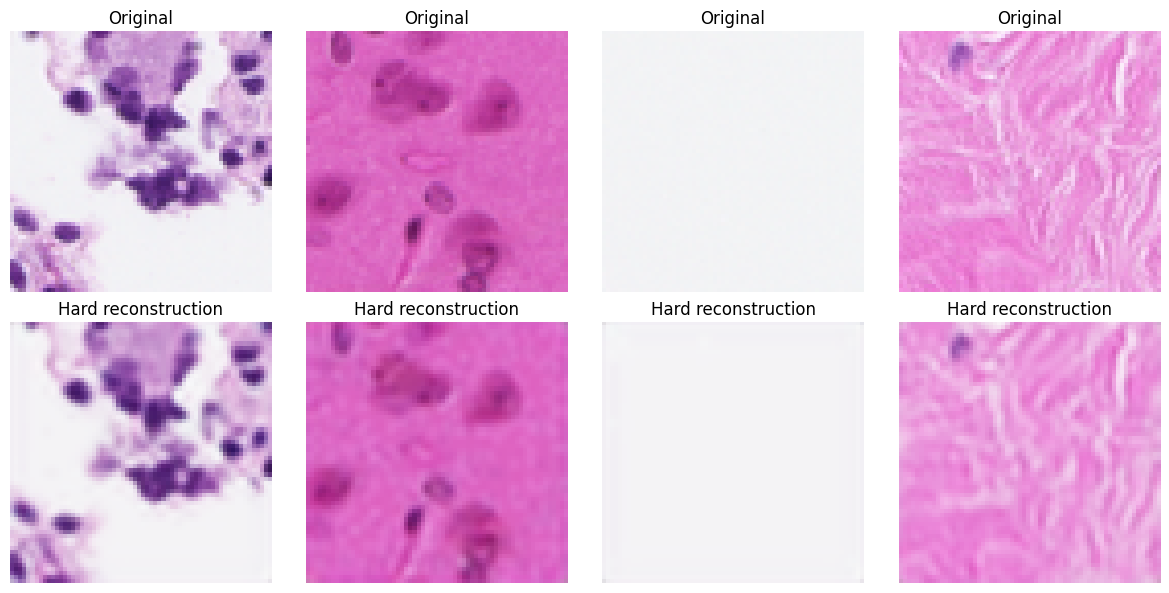

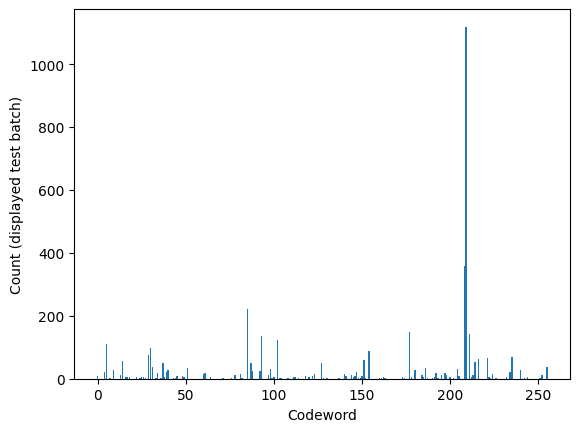

Used codewords in displayed batch: 120 / 256


In [28]:
SELECTED_CHECKPOINT = RUN_DIR / 'best.pt'     # replace with a validation-selected sweep checkpoint if needed
model, checkpoint = load_checkpoint(SELECTED_CHECKPOINT, soft_quantize, DEVICE)
test_metrics = evaluate(model, loaders['test'], DEVICE, checkpoint['train_config']['rate_weight'])
print('Selected epoch:', checkpoint['epoch'])
print(json.dumps(test_metrics, indent=2))
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(dict(checkpoint=str(SELECTED_CHECKPOINT), **test_metrics), indent=2))

images = next(iter(loaders['test']))[:4].to(DEVICE)
with torch.no_grad():
    result = model(images)
fig, axes = plt.subplots(2, len(images), figsize=(3 * len(images), 6), squeeze=False)
for i in range(len(images)):
    axes[0, i].imshow(images[i].cpu().permute(1, 2, 0)); axes[0, i].set_title('Original')
    axes[1, i].imshow(result['reconstruction'][i].cpu().permute(1, 2, 0)); axes[1, i].set_title('Hard reconstruction')
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout(); plt.savefig(RUN_DIR / 'reconstructions.png'); plt.show()
counts = torch.bincount(result['indices'].flatten(), minlength=model.config['codebook_size']).cpu()
plt.bar(range(len(counts)), counts); plt.xlabel('Codeword'); plt.ylabel('Count (displayed test batch)'); plt.show()
print('Used codewords in displayed batch:', int((counts > 0).sum()), '/', len(counts))

## 9. Saved bitstream vs JPEG (Part 4 groundwork)

DNN rate = measured compressed **latent payload** bytes; JPEG rate = complete JPEG file bytes (4:4:4, `optimize=False`); the shared checkpoint is excluded from both. Rates generally do not overlap, so this is not a matched-bitrate claim.

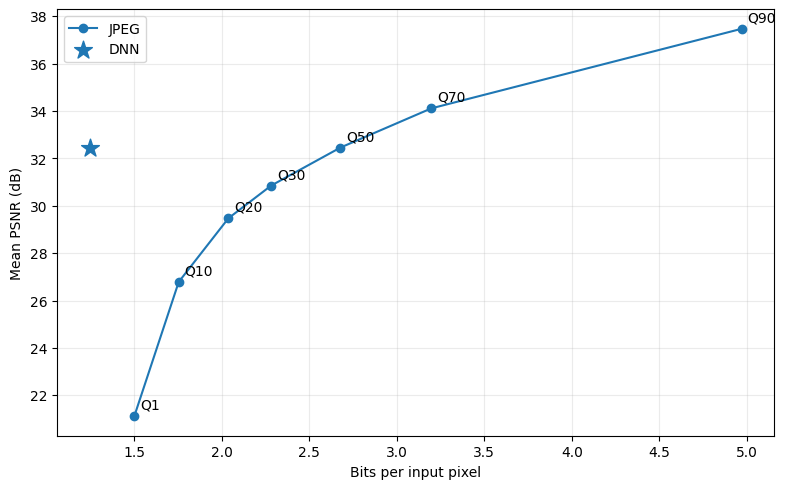

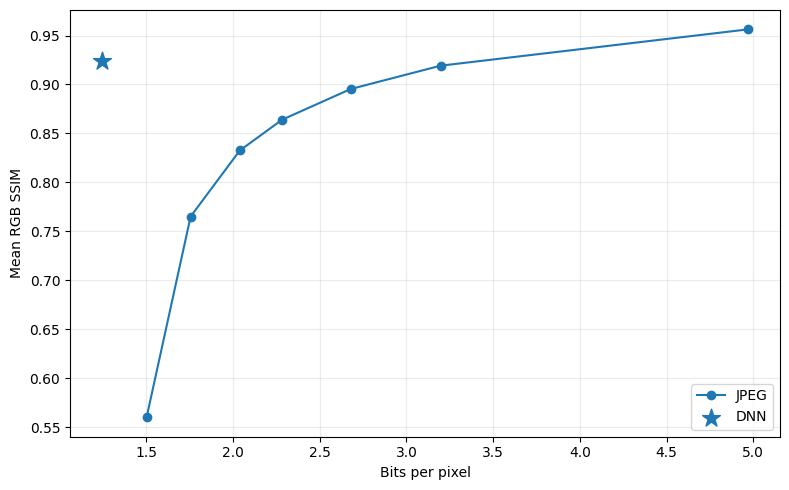

DNN         256 images | 1.2457 bpp | 32.43 dB | SSIM=0.9242
JPEG Q1     256 images | 1.5013 bpp | 21.11 dB | SSIM=0.5599
JPEG Q10    256 images | 1.7551 bpp | 26.79 dB | SSIM=0.7651
JPEG Q20    256 images | 2.0389 bpp | 29.48 dB | SSIM=0.8326
JPEG Q30    256 images | 2.2831 bpp | 30.86 dB | SSIM=0.8640
JPEG Q50    256 images | 2.6785 bpp | 32.46 dB | SSIM=0.8954
JPEG Q70    256 images | 3.1971 bpp | 34.12 dB | SSIM=0.9192
JPEG Q90    256 images | 4.9683 bpp | 37.47 dB | SSIM=0.9563
DNN coding modes: {'zlib': 256, 'arithmetic-left': 0, 'arithmetic-up': 0}
DNN bpp counts compressed latent bytes only; JPEG bpp counts complete JPEG bytes.
Codewords used over evaluation set: 233/256
DNN estimated bpp: 1.8434938644059002
Rates may not overlap: this is not a matched-bitrate superiority claim.
Shared checkpoint bytes (excluded from bpp): 790937


In [29]:
import comparison
compare_jpeg = partial(comparison.compare_jpeg, **student_metrics)
visualize_decoded = partial(comparison.visualize_decoded, **student_metrics)
COMPARISON_DIR = RUN_DIR / 'jpeg_comparison'
comparison_summary, comparison_examples = compare_jpeg(
    model, loaders['test'], DEVICE, COMPARISON_DIR,
    qualities=(1, 10, 20, 30, 50, 70, 90), examples=4)
print('Shared checkpoint bytes (excluded from bpp):', Path(SELECTED_CHECKPOINT).stat().st_size)

Decoded from: /content/dnn_compression_notebook/runs/solution_larger_20261114_202511_529256/jpeg_comparison/image_0.ecvq
Saved: /content/dnn_compression_notebook/runs/solution_larger_20261114_202511_529256/jpeg_comparison/decoded_image.png


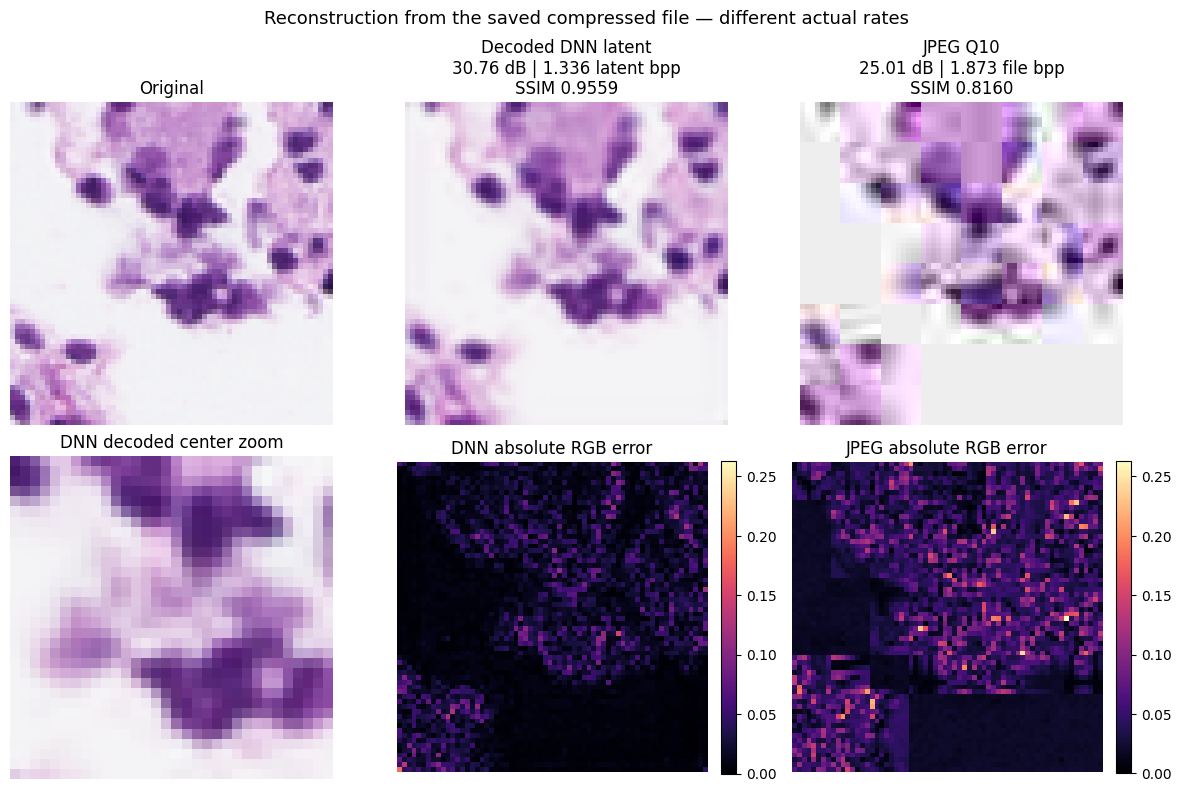

In [30]:
decoder_model, _ = load_checkpoint(SELECTED_CHECKPOINT, soft_quantize, DEVICE)
decoded_image = visualize_decoded(decoder_model, COMPARISON_DIR / 'image_0.ecvq',
                                  COMPARISON_DIR / 'image_0_original.png', COMPARISON_DIR, jpeg_quality=10)

## 10. Reproducibility record and download

In [31]:
record = dict(
    seed=SEED, mode=MODE, device=str(DEVICE), torch=torch.__version__, torchmetrics=torchmetrics.__version__,
    gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    data_root=str(DATA_ROOT), split_rule='predefined train/val/test directories (manifest in runs/shared_data_splits.json)',
    split_sizes_full={s: len(v) for s, v in splits.items()},
    used_crops={s: len(l.dataset) for s, l in loaders.items()},
    data_config=DATA_CONFIG, limits=LIMITS, test_offset=TEST_OFFSET, model_config=MODEL_CONFIG, train_config=TRAIN_CONFIG,
    objective='MSE + w_cb*L_codebook + lambda*R_soft (L_LPIPS / L_GAN not used)', codebook_loss=CODEBOOK_LOSS,
    entropy_model='context-free learnable prior r=softmax(prior_logits); Eq. 7 with empty conditioning set; stored rate measured with zlib',
    warm_start=dict(enabled=USE_WARM_START, epochs=8, max_vectors=32768),
    codebook=dict(K=MODEL_CONFIG['codebook_size'], dim=MODEL_CONFIG['latent_dim'], bits_per_index=math.ceil(math.log2(MODEL_CONFIG['codebook_size']))),
    rate_accounting='DNN bpp = compressed latent payload bytes*8/(H*W), header & checkpoint excluded; JPEG bpp = full file bytes (4:4:4, optimize=False)',
    index_decoding_check='decompress(compress(x)) == model(x) reconstruction, max abs diff < 1e-4 on 32 test crops',
    run_dir=str(RUN_DIR))
(RUN_DIR / 'part3_reproducibility.json').write_text(json.dumps(record, indent=2, default=str))
print(json.dumps(record, indent=2, default=str)[:1500])

# bundle figures / json / small tables for the GitHub repo (checkpoints are small too)
import shutil
bundle = shutil.make_archive('/content/part3_results' if IN_COLAB else str(Path.cwd() / 'part3_results'), 'zip', RUN_DIR)
print('Archive:', bundle)
if IN_COLAB:
    colab_files.download(bundle)

{
  "seed": 1512,
  "mode": "larger",
  "device": "cuda",
  "torch": "2.14.1+cu130",
  "torchmetrics": "1.9.0",
  "gpu": "Tesla T4",
  "data_root": "/content/data/data_1um_bicubic",
  "split_rule": "predefined train/val/test directories (manifest in runs/shared_data_splits.json)",
  "split_sizes_full": {
    "train": 12616,
    "val": 1576,
    "test": 1576
  },
  "used_crops": {
    "train": 1024,
    "val": 128,
    "test": 256
  },
  "data_config": {
    "crop_size": 64,
    "batch_size": 32
  },
  "limits": {
    "train": 1024,
    "val": 128,
    "test": 256
  },
  "test_offset": 128,
  "model_config": {
    "width": 64,
    "latent_dim": 16,
    "levels": 1,
    "codebook_size": 256,
    "straight_through": true
  },
  "train_config": {
    "epochs": 80,
    "lr": 0.0002,
    "rate_weight": 0.001,
    "codebook_loss": {
      "weight": 1.0,
      "beta": 0.25
    },
    "temperature_start": 0.02934122271835804,
    "temperature_end": 0.0058682445436716085
  },
  "objective": "MSE

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>